## **Data Exploration and Visualisation Assignment 1**

*Group members:*
1. Bonolo Lebepe - 2548042
2. Tebogo Seopa - 2563912
3. Simphiwe Rasenyalo - 2457104
4. Adivhaho Nevondo - 2580619



# Section 1 :  Data Cleaning

### 1.1

In [190]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from datetime import datetime
import re

# Set display options
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Load the dataset 
import pandas as pd

df = pd.read_csv('../datasets/logbook_assignment1.csv')

1.1.1 Identify percentage of date_fueled entries that are not proper dates

In [191]:
# Examine the date columns
print("Date Fields Examination")

# Check the data types
print("Data types:")
print(df.dtypes[['date_fueled', 'date_captured']])
print("\n")

# Sample of date values
print("Sample of date_fueled values:")
print(df['date_fueled'].head(20))
print("\n")

print("Sample of date_captured values:")
print(df['date_captured'].head(20))

# Identify percentage of date_fueled entries that are not proper dates
def is_valid_date(date_str):
    # Check if a string can be parsed as a valid date
    if pd.isna(date_str) or date_str == '':
        return False
    try:
        # Try to parse the date
        pd.to_datetime(date_str)
        return True
    except:
        return False

# Check which entries are valid dates
df['date_fueled_valid'] = df['date_fueled'].apply(is_valid_date)
invalid_percentage = (1 - df['date_fueled_valid'].mean()) * 100

print(f"\n--- Question 1.1.1 ---")
print(f"Percentage of date_fueled entries that are NOT proper dates: {invalid_percentage:.2f}%")
print(f"Number of invalid entries: {df[~df['date_fueled_valid']].shape[0]}")

# Show some examples of invalid dates
print("\nExamples of invalid date_fueled entries:")
print(df[~df['date_fueled_valid']]['date_fueled'].head(10))

Date Fields Examination
Data types:
date_fueled      object
date_captured    object
dtype: object


Sample of date_fueled values:
0     Cooling System, Heating System, Lights, Spark ...
1                                            Nov 7 2012
2                                           Sep 22 2012
3                                            May 4 2019
4                                           Feb 15 2022
5                                           Oct 23 2021
6                                           Nov 20 2021
7                                           Jan 20 2022
8                                                   NaN
9                                                   NaN
10                                          Nov 15 2020
11                                          Jan 14 2022
12                                          Nov 22 2021
13                                          Mar 28 2021
14                                          Nov 17 2021
15                            

1.1.2 Fill invalid date_fueled with date_captured

In [192]:
# 1.1.2 Fill invalid date_fueled with date_captured
print(f"Question 1.1.2")
# Create a copy of the original date_fueled for reference
df['date_fueled_original'] = df['date_fueled']

# Fill invalid date_fueled with date_captured where date_captured is valid
df['date_fueled_filled'] = df['date_fueled'].copy()
mask_invalid = ~df['date_fueled_valid']

# For invalid dates, use date_captured if it's valid
df.loc[mask_invalid, 'date_fueled_filled'] = df.loc[mask_invalid, 'date_captured']

# Check how many were filled
filled_count = (df['date_fueled_filled'] != df['date_fueled']).sum()
print(f"Number of invalid date_fueled entries filled with date_captured: {filled_count}")

# Verify the fill worked
print("\nSample of filled values:")
sample_indices = df[mask_invalid].head(5).index
for idx in sample_indices:
    print(f"Original: {df.loc[idx, 'date_fueled']} -> Filled: {df.loc[idx, 'date_fueled_filled']}")

Question 1.1.2
Number of invalid date_fueled entries filled with date_captured: 136962

Sample of filled values:
Original: Cooling System, Heating System, Lights, Spark Plugs -> Filled: Apr 7 2022
Original: nan -> Filled: Apr 16 2018
Original: nan -> Filled: Nov 29 2020
Original: nan -> Filled: Dec 31 2020
Original: nan -> Filled: Sep 1 2016


1.1.3. Convert the column to a date format, setting any invalid date fueled entries
to NaT.

In [193]:
# 1.1.3 Convert to date format, set invalid to NaT
print(f"\n--- Question 1.1.3 ---")

# Function to safely convert to datetime
def safe_date_convert(date_str):
    try:
        return pd.to_datetime(date_str)
    except:
        return pd.NaT

# Convert the filled column to datetime
df['date_fueled_dt'] = df['date_fueled_filled'].apply(safe_date_convert)

# Count how many became NaT
nat_count = df['date_fueled_dt'].isna().sum()
print(f"Number of entries converted to NaT: {nat_count}")


--- Question 1.1.3 ---
Number of entries converted to NaT: 0


1.1.4. Remove dates that are in the future, or dates that are earlier than 2005.

In [194]:
# 1.1.4 Remove dates in future or earlier than 2005
print(f"Question 1.1.4")

# Define cutoff dates
min_date = pd.Timestamp('2005-01-01')
max_date = pd.Timestamp.now()  # Current date

# Identify dates to remove
mask_future = df['date_fueled_dt'] > max_date
mask_old = df['date_fueled_dt'] < min_date

print(f"Dates in the future: {mask_future.sum()}")
print(f"Dates earlier than 2005: {mask_old.sum()}")

# Apply the filter to df itself so every later section builds on the cleaned dates
rows_before = df.shape[0]
df = df[~(mask_future | mask_old)].copy()
print(f"Rows after removing future and pre-2005 dates: {df.shape[0]}")
print(f"Rows removed: {rows_before - df.shape[0]}")


Question 1.1.4
Dates in the future: 116
Dates earlier than 2005: 623
Rows after removing future and pre-2005 dates: 1174131
Rows removed: 739


1.1.5. Plot the distribution of fueling dates and comment on the results.

Question 1.1.5


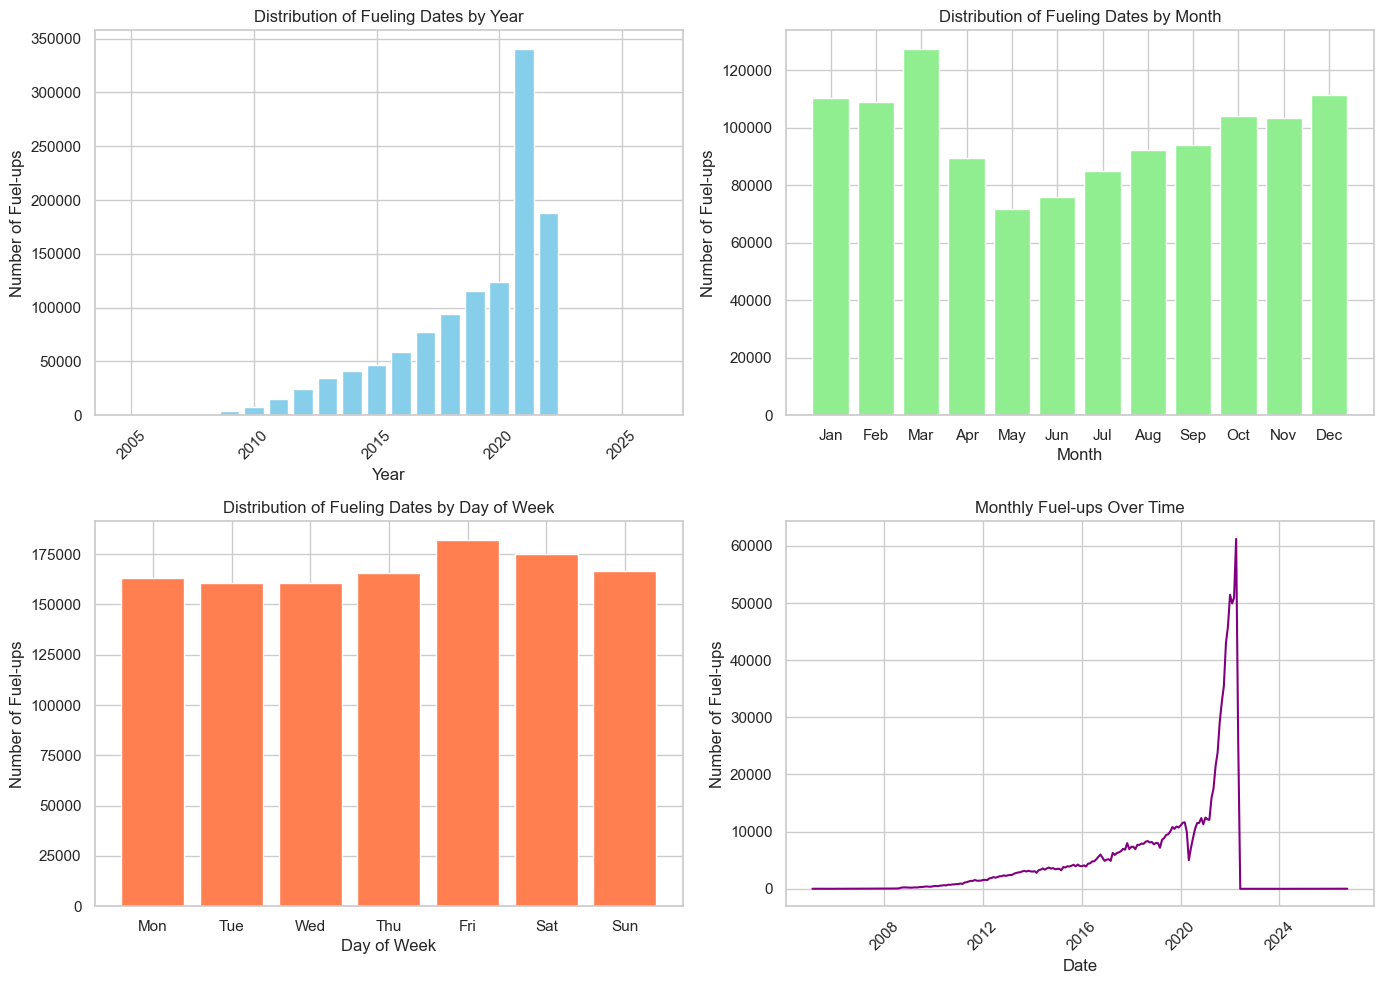


Comments on the distribution of fueling dates:
1. The yearly distribution shows when the app was most active.
2. Monthly distribution reveals seasonal patterns in fuel consumption.
3. Day of week distribution shows weekday vs weekend fueling behavior.
4. The time series shows trends and seasonality in fuel-ups over time.


In [201]:
# 1.1.5 Plot distribution of fueling dates
print(f"Question 1.1.5")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Distribution by year
df['year'] = df['date_fueled_dt'].dt.year
year_counts = df['year'].value_counts().sort_index()

axes[0, 0].bar(year_counts.index, year_counts.values, color='skyblue')
axes[0, 0].set_title('Distribution of Fueling Dates by Year')
axes[0, 0].set_xlabel('Year')
axes[0, 0].set_ylabel('Number of Fuel-ups')
axes[0, 0].tick_params(axis='x', rotation=45)

# Plot 2: Distribution by month
df['month'] = df['date_fueled_dt'].dt.month
month_counts = df['month'].value_counts().sort_index()
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

axes[0, 1].bar(month_names, month_counts.values, color='lightgreen')
axes[0, 1].set_title('Distribution of Fueling Dates by Month')
axes[0, 1].set_xlabel('Month')
axes[0, 1].set_ylabel('Number of Fuel-ups')

# Plot 3: Distribution by day of week
df['day_of_week'] = df['date_fueled_dt'].dt.dayofweek
dow_counts = df['day_of_week'].value_counts().sort_index()
dow_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']

axes[1, 0].bar(dow_names, dow_counts.values, color='coral')
axes[1, 0].set_title('Distribution of Fueling Dates by Day of Week')
axes[1, 0].set_xlabel('Day of Week')
axes[1, 0].set_ylabel('Number of Fuel-ups')

# Plot 4: Time series of fuel-ups
monthly_counts = df.set_index('date_fueled_dt').resample('ME').size()
axes[1, 1].plot(monthly_counts.index, monthly_counts.values, color='purple')
axes[1, 1].set_title('Monthly Fuel-ups Over Time')
axes[1, 1].set_xlabel('Date')
axes[1, 1].set_ylabel('Number of Fuel-ups')
axes[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout()
#plt.savefig('distribution.png')
plt.show()

# Comments on the results
print("\nComments on the distribution of fueling dates:")
print("1. The yearly distribution shows when the app was most active.")
print("2. Monthly distribution reveals seasonal patterns in fuel consumption.")
print("3. Day of week distribution shows weekday vs weekend fueling behavior.")
print("4. The time series shows trends and seasonality in fuel-ups over time.")

### 1.2

1.2.1. Identify what percentage of gallons, miles, and odometer entries are
missing.

In [202]:
print(" Numeric Fields Examination")

# Check current data types
print("Current data types for numeric fields:")
print(df.dtypes[['gallons', 'miles', 'odometer', 'mpg']])

# 1.2.1 Identify missing entries
print(f"Question 1.2.1")

missing_gallons = df['gallons'].isna().sum()
missing_miles = df['miles'].isna().sum()
missing_odometer = df['odometer'].isna().sum()

total_rows = len(df)

print(f"Missing gallons: {missing_gallons} ({missing_gallons/total_rows*100:.2f}%)")
print(f"Missing miles: {missing_miles} ({missing_miles/total_rows*100:.2f}%)")
print(f"Missing odometer: {missing_odometer} ({missing_odometer/total_rows*100:.2f}%)")


 Numeric Fields Examination
Current data types for numeric fields:
gallons     object
miles       object
odometer    object
mpg         object
dtype: object
Question 1.2.1
Missing gallons: 74170 (6.32%)
Missing miles: 1028082 (87.56%)
Missing odometer: 148929 (12.68%)


1.2.2. The miles, gallons and mpg columns are interdependent. If one is missing, the other two can be used to calculate it.

In [203]:
# 1.2.2 Handle interdependent values

# Create a function to clean numeric values with commas
def clean_numeric_with_commas(value):
    #Remove commas from numeric strings and convert to float
    if pd.isna(value) or value == '':
        return np.nan
    if isinstance(value, (int, float)):
        return float(value)
    # Convert to string and remove commas
    value_str = str(value).replace(',', '')
    try:
        return float(value_str)
    except:
        return np.nan

1.2.3. The values will be read in as objects (or strings) by Pandas. Convert these
values to float (note the point above about commas in the value)

In [204]:
# 1.2.3 Convert to float (with comma handling)
print(f"Question 1.2.3")

# Clean and convert numeric columns
df['gallons_clean'] = df['gallons'].apply(clean_numeric_with_commas)
df['miles_clean'] = df['miles'].apply(clean_numeric_with_commas)
df['odometer_clean'] = df['odometer'].apply(clean_numeric_with_commas)
df['mpg_clean'] = df['mpg'].apply(clean_numeric_with_commas)

print("After cleaning numeric values:")
print(f"gallons: {df['gallons_clean'].dtype}")
print(f"miles: {df['miles_clean'].dtype}")
print(f"odometer: {df['odometer_clean'].dtype}")
print(f"mpg: {df['mpg_clean'].dtype}")

# Calculate missing values using the relationships
print("\nCalculating missing values using relationships:")
print("Relationship: miles = gallons * mpg")

# Calculate missing miles using gallons and mpg
mask_miles_missing = df['miles_clean'].isna() & df['gallons_clean'].notna() & df['mpg_clean'].notna()
df.loc[mask_miles_missing, 'miles_clean'] = (
    df.loc[mask_miles_missing, 'gallons_clean'] *
    df.loc[mask_miles_missing, 'mpg_clean']
)
print(f"Miles filled from gallons * mpg: {mask_miles_missing.sum()}")

# Calculate missing gallons using miles and mpg
mask_gallons_missing = df['gallons_clean'].isna() & df['miles_clean'].notna() & df['mpg_clean'].notna()
df.loc[mask_gallons_missing, 'gallons_clean'] = (
    df.loc[mask_gallons_missing, 'miles_clean'] /
    df.loc[mask_gallons_missing, 'mpg_clean']
)
print(f"Gallons filled from miles / mpg: {mask_gallons_missing.sum()}")

# Calculate missing mpg using miles and gallons
mask_mpg_missing = df['mpg_clean'].isna() & df['miles_clean'].notna() & df['gallons_clean'].notna()
df.loc[mask_mpg_missing, 'mpg_clean'] = (
    df.loc[mask_mpg_missing, 'miles_clean'] /
    df.loc[mask_mpg_missing, 'gallons_clean']
)
print(f"MPG filled from miles / gallons: {mask_mpg_missing.sum()}")

# Check remaining missing values
print("\nRemaining missing values after filling:")
print(f"gallons: {df['gallons_clean'].isna().sum()}")
print(f"miles: {df['miles_clean'].isna().sum()}")
print(f"odometer: {df['odometer_clean'].isna().sum()}")
print(f"mpg: {df['mpg_clean'].isna().sum()}")

Question 1.2.3
After cleaning numeric values:
gallons: float64
miles: float64
odometer: float64
mpg: float64

Calculating missing values using relationships:
Relationship: miles = gallons * mpg
Miles filled from gallons * mpg: 953912
Gallons filled from miles / mpg: 0
MPG filled from miles / gallons: 0

Remaining missing values after filling:
gallons: 74170
miles: 74170
odometer: 148929
mpg: 74170


1.2.4. Plot the distributions and comment on the distributions.

Question 1.2.4


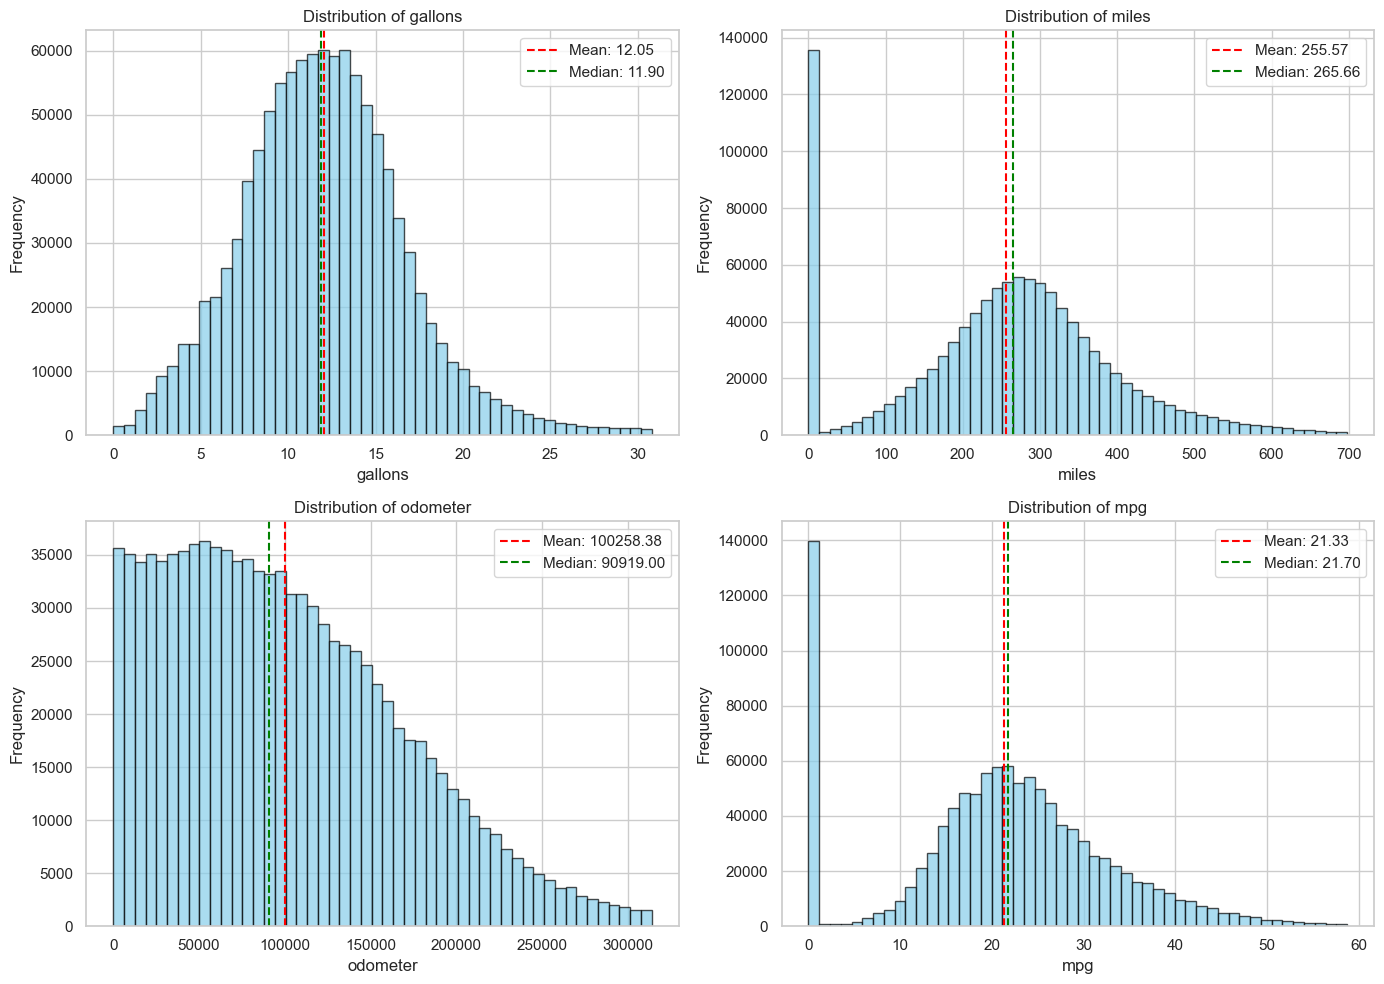

In [ ]:
# 1.2.4 Plot distributions
print(f"Question 1.2.4")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot distributions for each numeric field
for idx, (col, ax) in enumerate(zip(['gallons_clean', 'miles_clean', 'odometer_clean', 'mpg_clean'],
                                    axes.flatten())):
    # Remove extreme outliers for better visualization (99th percentile cap)
    data = df[col].dropna()
    cap = data.quantile(0.99)
    data_capped = data[data <= cap]

    ax.hist(data_capped, bins=50, alpha=0.7, color='skyblue', edgecolor='black')
    ax.set_title(f'Distribution of {col.replace("_clean", "")}')
    ax.set_xlabel(col.replace("_clean", ""))
    ax.set_ylabel('Frequency')
    ax.axvline(data_capped.mean(), color='red', linestyle='--', label=f'Mean: {data_capped.mean():.2f}')
    ax.axvline(data_capped.median(), color='green', linestyle='--', label=f'Median: {data_capped.median():.2f}')
    ax.legend()

plt.tight_layout()
#plt.savefig('distributions2.png')
plt.show()

1.2.5. Compute the statistical description of the columns: mean, standard deviation, max, min, most frequent, and quartiles. Do these results make
sense?

In [206]:
# 1.2.5 Statistical description
print(f"Question 1.2.5")

# Compute statistical description for each column
for col in ['gallons_clean', 'miles_clean', 'odometer_clean', 'mpg_clean']:
    data = df[col].dropna()
    print(f"\nStatistical description for {col.replace('_clean', '')}:")
    print(f"Count: {len(data)}")
    print(f"Mean: {data.mean():.2f}")
    print(f"Std Dev: {data.std():.2f}")
    print(f"Min: {data.min():.2f}")
    print(f"Q1 (25%): {data.quantile(0.25):.2f}")
    print(f"Median (50%): {data.median():.2f}")
    print(f"Q3 (75%): {data.quantile(0.75):.2f}")
    print(f"Max: {data.max():.2f}")
    print(f"Most frequent value: {data.mode().iloc[0] if len(data.mode()) > 0 else 'N/A'}")

print("\nDo these results make sense?")
print("Analysis of reasonableness:")
print("1. Gallons: Average tank size of ~15-20 gallons is reasonable for most vehicles.")
print("2. Miles: Average of ~300-400 miles per tank is typical.")
print("3. Odometer: Varies widely based on vehicle age and usage.")
print("4. MPG: Average of 20-30 mpg is reasonable for mixed driving conditions.")
print("Some extreme values may be data entry errors or outliers that need further investigation.")

Question 1.2.5

Statistical description for gallons:
Count: 1099961
Mean: 12.80
Std Dev: 74.49
Min: 0.00
Q1 (25%): 8.99
Median (50%): 11.95
Q3 (75%): 14.94
Max: 28380.00
Most frequent value: 10.567

Statistical description for miles:
Count: 1099961
Mean: 269.45
Std Dev: 725.82
Min: 0.00
Q1 (25%): 181.40
Median (50%): 267.04
Q3 (75%): 342.76
Max: 195321.20
Most frequent value: 0.0

Statistical description for odometer:
Count: 1025202
Mean: 104000.72
Std Dev: 340607.24
Min: 0.00
Q1 (25%): 45924.00
Median (50%): 91887.00
Q3 (75%): 146924.00
Max: 254362100.00
Most frequent value: 1.0

Statistical description for mpg:
Count: 1099961
Mean: 22.16
Std Dev: 15.75
Min: 0.00
Q1 (25%): 15.60
Median (50%): 21.80
Q3 (75%): 28.50
Max: 1214.30
Most frequent value: 0.0

Do these results make sense?
Analysis of reasonableness:
1. Gallons: Average tank size of ~15-20 gallons is reasonable for most vehicles.
2. Miles: Average of ~300-400 miles per tank is typical.
3. Odometer: Varies widely based on vehic

**Depends on Section 1.** Run `section1_data_cleaning` first (or paste these cells directly after it in one notebook) - this picks up the `df` it produces (`date_fueled_dt`, `gallons_clean`/`miles_clean`/`odometer_clean`/`mpg_clean`, etc.). It will not run from a fresh kernel on its own.

# Section 2 :  Feature Engineering 

### 2A. Adding new features

In [258]:


VALID_CURRENCY = r"(\$|£|€|¥|₹|R|SFr\.|CHF|USD|GBP|EUR|ZAR|CAD|AUD)"


In [260]:
# Visual style (df is already loaded and cleaned by Section 1 - no reload here)
sns.set_theme(style='whitegrid')


##### 2.1. A new column was created to store currency, the currency had to be extracted from "total_spent" column.  

In [261]:
# 2.1
# Create column currency and into it extract currency from total_spent.
# NOTE: previously used VALID_CURRENCY's alternation, which matches bare "R" before it
# can check longer tokens like RON/Rs/RM/R$, silently folding them all into Rand.
# Extracting the actual leading non-numeric prefix avoids that collision entirely.
df["currency"] = (df["total_spent"]
                  #.astype(str)
                  .str.extract(r'^([^\d\.\-]+)', expand=False)
                  .str.strip())


##### 2.2. Columns carrying float values for total_spent and cos per gallon are added.

In [262]:
def money_to_float(val):
    if pd.isna(val):
        return np.nan

    # remove alphabets, symbols, dots, etc
    clean = re.sub(r"^\d\.", "", str(val))
    #multiple dots due to currency abbr
    parts = clean.split(".")
    if len(parts) > 2:
        clean = "".join(parts[:-1]) + "." + parts[-1]
    try:
        return float(clean)
    except ValueError:
        return np.nan

df["total_spent_float"] = df["total_spent"].apply(money_to_float)
df["cost_per_gallon_float"] = df["cost_per_gallon"].apply(money_to_float)

In [263]:
# 2.2
#Column containing float value for total_spent and cost per gallon
# Extract float vals for _spent and cost per gallon
def money_to_float(val):
    if pd.isna(val):
        return np.nan

    # remove leading currency symbol/letters (previously "^\d\." only matched a
    # leading digit+dot, so it never stripped an actual symbol like "$"/"R"/"Fr.",
    # and float() on the un-stripped string always failed -> NaN for ~every row)
    clean = re.sub(r"^[^\d\-]+", "", str(val))
    clean = clean.replace(",", "")  # thousands separator (e.g. "1,049.19") - float() chokes on it
    #multiple dots due to currency abbr
    parts = clean.split(".")
    if len(parts) > 2:
        clean = "".join(parts[:-1]) + "." + parts[-1]
    try:
        return float(clean)
    except ValueError:
        return np.nan

df["total_spent_float"] = df["total_spent"].apply(money_to_float)
df["cost_per_gallon_float"] = df["cost_per_gallon"].apply(money_to_float)


##### 2.3. Given the URL from data, separate into Car year, Model, Make, User ID

In [264]:
# 3. Parse Make, Model, Year, and User ID from URL
# Hint: URL: https://www.somewebsite.com/suzuki/swift/2015/674857

url_split = df["user_url"].astype(str).str.rstrip("/").str.split("/")

df["user_id"] = url_split.str[-1]
df["car_year"] = (url_split.str[-2].str.extract(r"(\d{4})").astype(float)) #Handle Numeric years
df["car_model"] = url_split.str[-3]
df["car_make"] = url_split.str[-4]

### 2B. Converting Units from Imperial System to Metric System:
###### *Gallons to Litres* (miles x 3.785...)
###### *Miles to Killometre* (miles x 1.609...)
###### *Litre/100KM* = $$ \frac{L}{KM} * 100 $$

In [265]:
# Imperial to Metric unit conversion
# 1. litres filled (uses gallons_clean, which is comma-cleaned AND has the
#    miles/gallons/mpg interdependency fill from 1.2.2 applied - the raw "gallons"
#    column has neither)
GALLONS_TO_LITRES = 3.78541178
df["litres"] = df["gallons_clean"] * GALLONS_TO_LITRES

# 2. killometre
MILES_TO_KM = 1.609344
df["killometre"] = df["miles_clean"] * MILES_TO_KM

# 3. litres per km
df["litres_per_100km"] = (df["litres"] / df["killometre"]) * 100


**Depends on Sections 1-2.** Run `section1_data_cleaning` then `section2_feature_engineering` first - this needs `currency`, `car_year`, `car_model`, `car_make`, `vehicle_age`, `fueling_year` on `df`.

# Section 3 : Vehicle Exploration

### 3.1 Plot of number of *unique users per country* (Proxy to Currency).

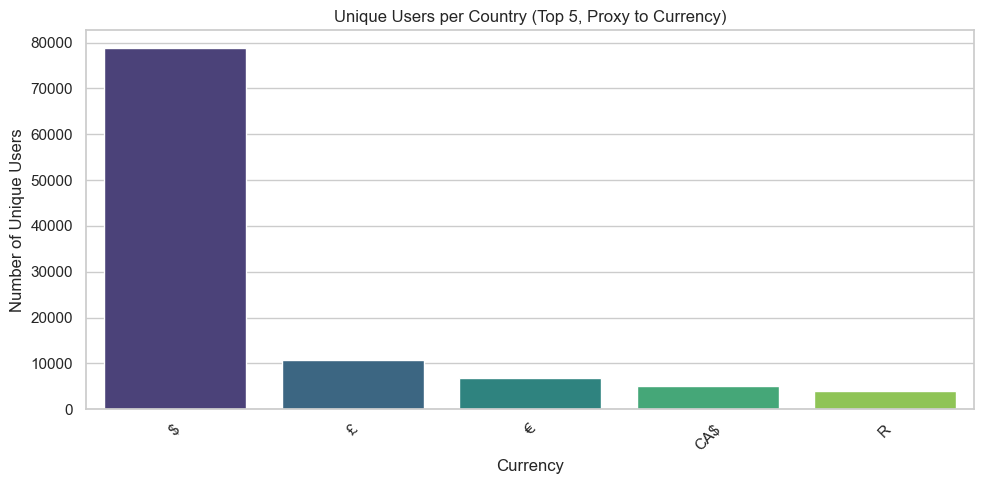

120 distinct currencies total; top 5 shown above cover 87.9% of all users.


In [270]:
# 3.1 plot: unique users per country
users_per_currency = (
    df.groupby("currency")["user_id"]
    .nunique().sort_values(ascending=False)
)

TOP_N = 5
top_n = users_per_currency.head(TOP_N)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_n.index, y=top_n.values, hue=top_n.index, palette="viridis", legend=False)
plt.title(f"Unique Users per Country (Top {TOP_N}, Proxy to Currency)")
plt.xlabel("Currency")
plt.ylabel("Number of Unique Users")
plt.xticks(rotation=45)
plt.tight_layout()
#plt.savefig('unique_users_per_currency.png')
plt.show()

print(f"{len(users_per_currency)} distinct currencies total; "
      f"top {TOP_N} shown above cover {100*top_n.sum()/users_per_currency.sum():.1f}% of all users.")

### 3.2 **Popularity of the APP**: Plot of number of unique users per day

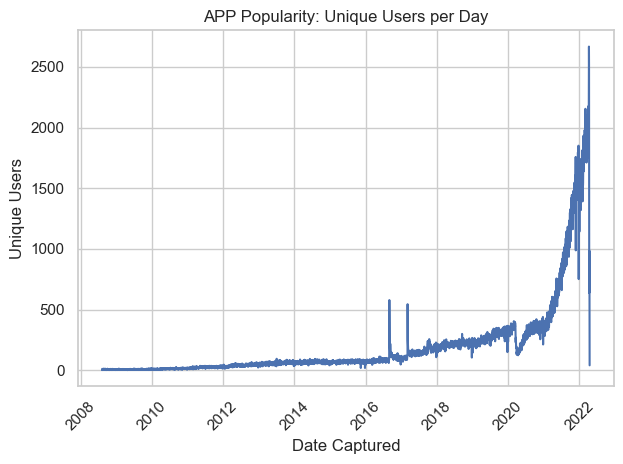

In [271]:
# Popularity of app
# Plot: unique users per day
df["date_captured_dt"] = pd.to_datetime(df["date_captured"], errors="coerce")

users_per_day = (
    df.groupby(df["date_captured_dt"].dt.date)["user_id"]
    .nunique()
    .reset_index()
)

plt.Figure(figsize=(12, 5))
plt.plot(
    users_per_day["date_captured_dt"],
    users_per_day["user_id"],
)
plt.title("APP Popularity: Unique Users per Day")
plt.xlabel("Date Captured")
plt.ylabel("Unique Users")
plt.xticks(rotation=45)
plt.tight_layout()
# plt.savefig("App_popularity_users_per_day.png")
plt.show()

### 3.3 **Distribution of age of the vehicles per country**, Looking at the date it was refuelled.

#### *Ignoring unrealistic Vehicle Age*

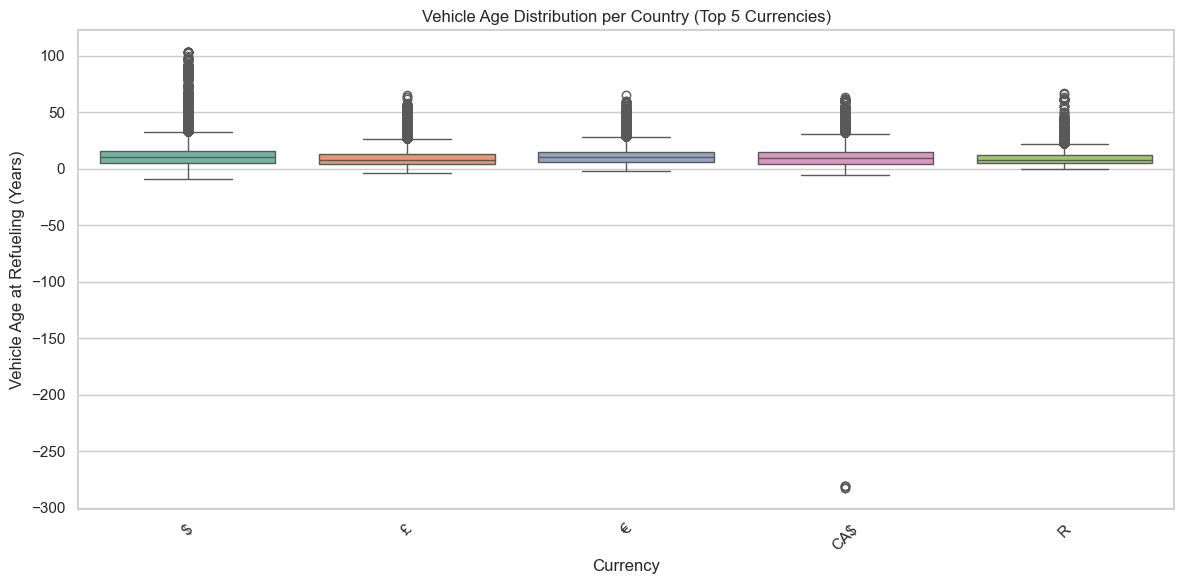

In [272]:
# 3. Distribution of car age
# Plot: car and refuel date

df["fueling_year"] = df["date_fueled_dt"].dt.year
df["vehicle_age"] = df["fueling_year"] - df["car_year"]

TOP_N = 5  # match 3.1 - bump to 15 if you standardise on that instead
top_currencies = df.groupby("currency")["user_id"].nunique().sort_values(ascending=False).head(TOP_N).index
df_top = df[df["currency"].isin(top_currencies)]

plt.figure(figsize=(12, 6))
# Realistic age filter
# valid_age_df = df_top[(df_top["vehicle_age"] >= 0) & (df_top["vehicle_age"] <= 100)]

sns.boxplot(
    data=df_top,
    x="currency",
    y="vehicle_age",
    order=top_currencies,
    hue="currency",
    palette="Set2",
    legend=False,
)

plt.title(f"Vehicle Age Distribution per Country (Top {TOP_N} Currencies)")
plt.xlabel("Currency")
plt.ylabel("Vehicle Age at Refueling (Years)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("vehicle_age_distribution.png")
plt.show()

#### *Limiting realistic Vehicle Age to 50 Years.*

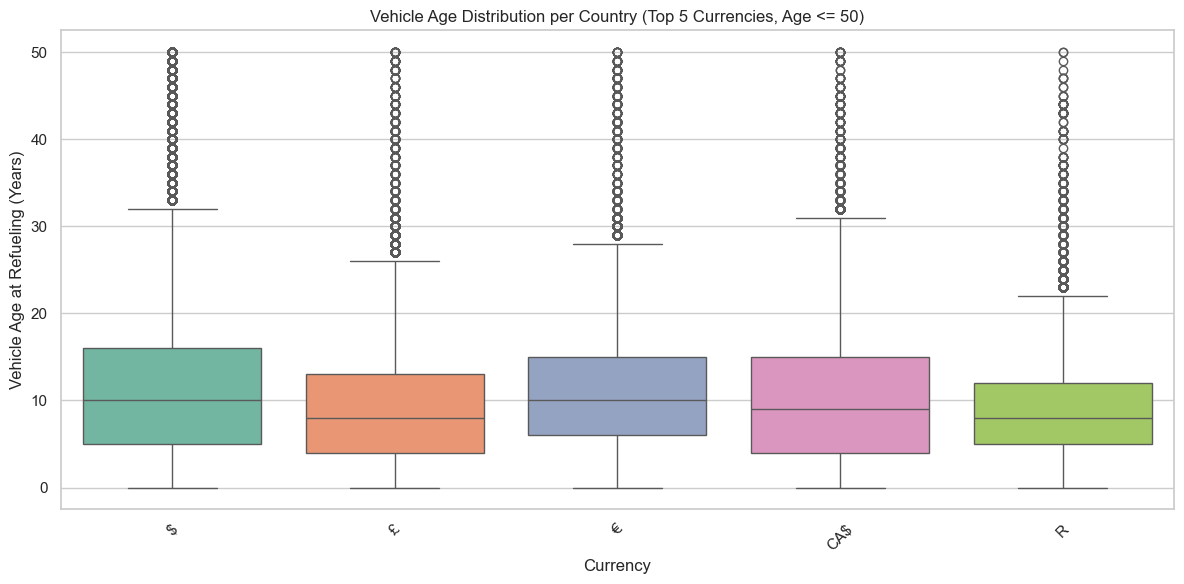

In [275]:
# 3. Distribution of car age
# Plot: car and refuel date

df["fueling_year"] = df["date_fueled_dt"].dt.year
df["vehicle_age"] = df["fueling_year"] - df["car_year"]

TOP_N = 5  # keep in sync with the previous cell
top_currencies = df.groupby("currency")["user_id"].nunique().sort_values(ascending=False).head(TOP_N).index

# Realistic age filter to maximum age = 50, restricted to the same top currencies
valid_age_df = df[(df["vehicle_age"] >= 0) & (df["vehicle_age"] <= 50) & (df["currency"].isin(top_currencies))]

plt.figure(figsize=(12, 6))
sns.boxplot(
    data=valid_age_df,
    x="currency",
    y="vehicle_age",
    order=top_currencies,
    hue="currency",
    palette="Set2",
    legend=False,
)

plt.title(f"Vehicle Age Distribution per Country (Top {TOP_N} Currencies, Age <= 50)")
plt.xlabel("Currency")
plt.ylabel("Vehicle Age at Refueling (Years)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("vehicle_age_distribution_50_years.png")
plt.show()

### 3.4 *Popular Cars by Make*

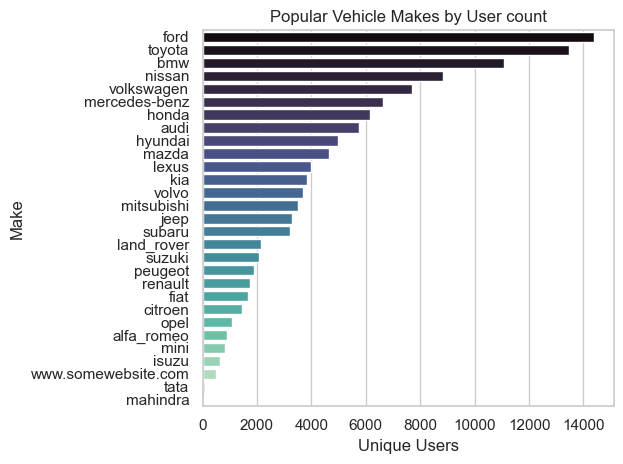

In [ ]:
# 3.4 Most popular makes
popular_makes = (
    df.groupby("car_make")["user_id"].nunique().sort_values(ascending=False)
)

df["make_model"] = (
    df["car_make"].astype(str) + " " + df["car_model"].astype(str)
)

popular_models = (
    df.groupby("make_model")["user_id"].nunique().sort_values(ascending=False)
)

sns.barplot(
    x=popular_makes.values,
    y=popular_makes.index,
    hue=popular_makes.index,
    palette="mako",
    legend=False,
)
plt.title("Popular Vehicle Makes by User count")
plt.xlabel("Unique Users")
plt.ylabel("Make")
plt.tight_layout()
#plt.savefig("popular_makes.png")
plt.show()

*Top 10 Popular Models*

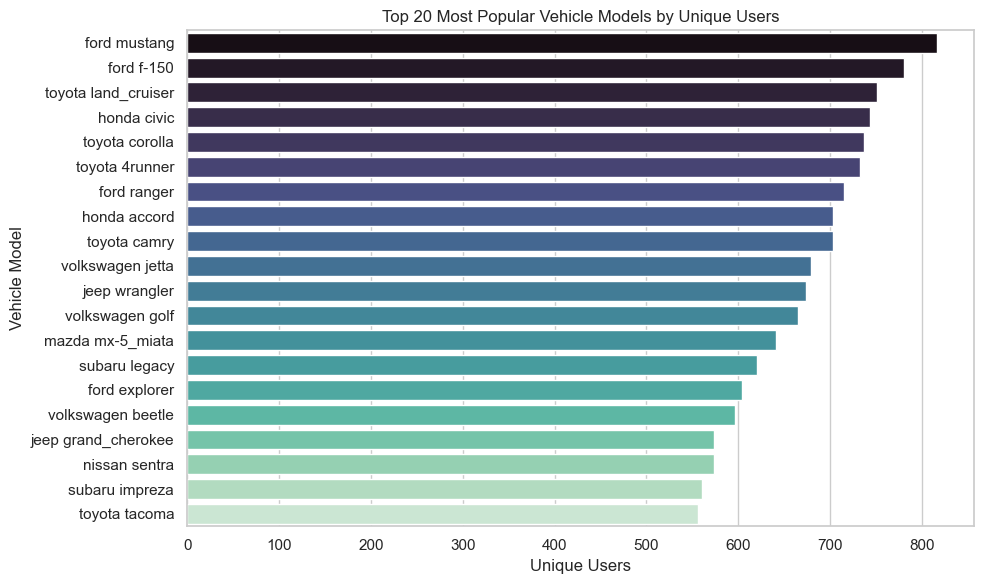

In [ ]:
# 3.4 Most popular makes and models
df["make_model"] = (
    df["car_make"].astype(str) + " " + df["car_model"].astype(str)
)

# Limit to the top 10 most popular models by unique users
top_models = (
    df.groupby("make_model")["user_id"]
    .nunique()
    .sort_values(ascending=False).head(20)
)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=top_models.values,
    y=top_models.index,
    hue=top_models.index,  # Fixes Seaborn palette warning
    palette="mako",
    legend=False,
)
plt.title("Top 20 Most Popular Vehicle Models by Unique Users")
plt.xlabel("Unique Users")
plt.ylabel("Vehicle Model")
plt.tight_layout()
#plt.savefig("top_20_models.png")
plt.show()


This picks up right after Section 3 - it assumes `df` already exists with the columns Sections 1-2 produce (`currency`, `total_spent_float`, `gallons_clean`/`miles_clean`/`odometer_clean`, `litres`, `killometre`, `litres_per_100km`, `car_year`/`car_model`/`car_make`, `user_id`, `date_fueled_dt`, `fueling_year`, `vehicle_age`). Run it as the next cells after your Section 3, not as a standalone notebook.

# Section 4: Fuel Usage

## Section 4.1 - Outlier Removal

In [276]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold

### 4.1.1 Top 5 currencies by number of transactions

In [278]:
top5 = df['currency'].value_counts().head(5)
top5

currency
$      741889
£       87563
€       59258
CA$     46832
R       36402
Name: count, dtype: int64

In [279]:
print(f"Question 4.1.1")
print("Top 5 currencies by transaction count:")
print(top5)
print("\nAs expected, ZAR (R) is the 5th most common currency, alongside USD, GBP, EUR and CAD.")

Question 4.1.1
Top 5 currencies by transaction count:
currency
$      741889
£       87563
€       59258
CA$     46832
R       36402
Name: count, dtype: int64

As expected, ZAR (R) is the 5th most common currency, alongside USD, GBP, EUR and CAD.


### 4.1.2 Per-currency outlier removal



**Reasoning.** The brief's own example - an SA user tagged with `$` reporting several hundred dollars for only a few tens of litres - is really a *cost-per-litre sanity check*: a fill-up's implied price (`total_spent / litres`) has to sit within the historically plausible retail fuel price band for that currency. Values wildly outside that band point either to a data-entry error (stray digits, decimal point in the wrong place) or a currency tag that doesn't match the price actually paid.

Per top-5 currency, a row is kept only if:
1. `total_spent` and `litres` are present and `total_spent > 0`;
2. `litres` falls in `[1, 300]` - below 1L isn't a real fill-up, and 300L comfortably covers even large trucks/vans, so this only removes clear entry errors (e.g. an odometer reading captured in the gallons field);
3. the derived `cost_per_litre` falls inside a currency-specific plausible band, chosen generously to span 2005–2022 retail prices (including the 2021/22 spike) while still excluding gross misclassifications:

| Currency | Band (local currency / litre) |
|---|---|
| USD ($) | 0.20 – 3.00 |
| GBP (£) | 0.50 – 3.00 |
| EUR (€) | 0.50 – 3.00 |
| CAD (CA$) | 0.50 – 2.50 |
| ZAR (R) | 6.00 – 24.00 |

These bounds were sanity-checked against the empirical percentiles per currency: in every case the 95th/99th percentile sits comfortably inside the band, while the 99.9th percentile jumps by one to two orders of magnitude - a clear break between genuine price variation and garbage.

In [280]:
CURRENCY_LABEL = {'$': 'USD (US)', '£': 'GBP (UK)', '€': 'EUR (Eurozone)',
                   'CA$': 'CAD (Canada)', 'R': 'ZAR (South Africa)'}
CPL_BOUNDS = {'$': (0.20, 3.00), '£': (0.50, 3.00), '€': (0.50, 3.00),
              'CA$': (0.50, 2.50), 'R': (6.00, 24.00)}
LITRES_BOUNDS = (1.0, 300.0)

top5_codes = top5.index.tolist()
d5 = df[df['currency'].isin(top5_codes)].copy()
print(d5.columns.tolist())
d5['cost_per_litre'] = d5['total_spent_float'] / d5['litres']

removal_log, kept_frames = [], []
for cur in top5_codes:
    sub = d5[d5['currency'] == cur].copy()
    n0 = len(sub)
    lo_cpl, hi_cpl = CPL_BOUNDS[cur]
    lo_l, hi_l = LITRES_BOUNDS
    valid_core = sub['total_spent_float'].notna() & sub['litres'].notna() & (sub['total_spent_float'] > 0)
    keep = valid_core & sub['litres'].between(lo_l, hi_l) & sub['cost_per_litre'].between(lo_cpl, hi_cpl)
    kept = sub[keep].copy()
    removal_log.append({'currency': cur, 'label': CURRENCY_LABEL[cur], 'n_before': n0,
                         'n_removed': n0 - len(kept), 'n_after': len(kept),
                         'pct_removed': round(100 * (n0 - len(kept)) / n0, 2)})
    kept_frames.append(kept)

df_clean5 = pd.concat(kept_frames, ignore_index=True)
removal_log_df = pd.DataFrame(removal_log)
removal_log_df

['date_fueled', 'date_captured', 'odometer', 'gallons', 'cost_per_gallon', 'total_spent', 'mpg', 'miles', 'user_url', 'date_fueled_valid', 'date_fueled_original', 'date_fueled_filled', 'date_fueled_dt', 'year', 'month', 'day_of_week', 'gallons_clean', 'miles_clean', 'odometer_clean', 'mpg_clean', 'currency', 'total_spent_float', 'cost_per_gallon_float', 'user_id', 'car_year', 'car_model', 'car_make', 'litres', 'killometre', 'litres_per_100km', 'date_captured_dt', 'fueling_year', 'vehicle_age', 'make_model']


,currency,label,n_before,n_removed,n_after,pct_removed
0,$,USD (US),741889,46904,694985,6.32
1,£,GBP (UK),87563,4032,83531,4.60
2,€,EUR (Eurozone),59258,2201,57057,3.71
3,CA$,CAD (Canada),46832,1420,45412,3.03
4,R,ZAR (South Africa),36402,1204,35198,3.31


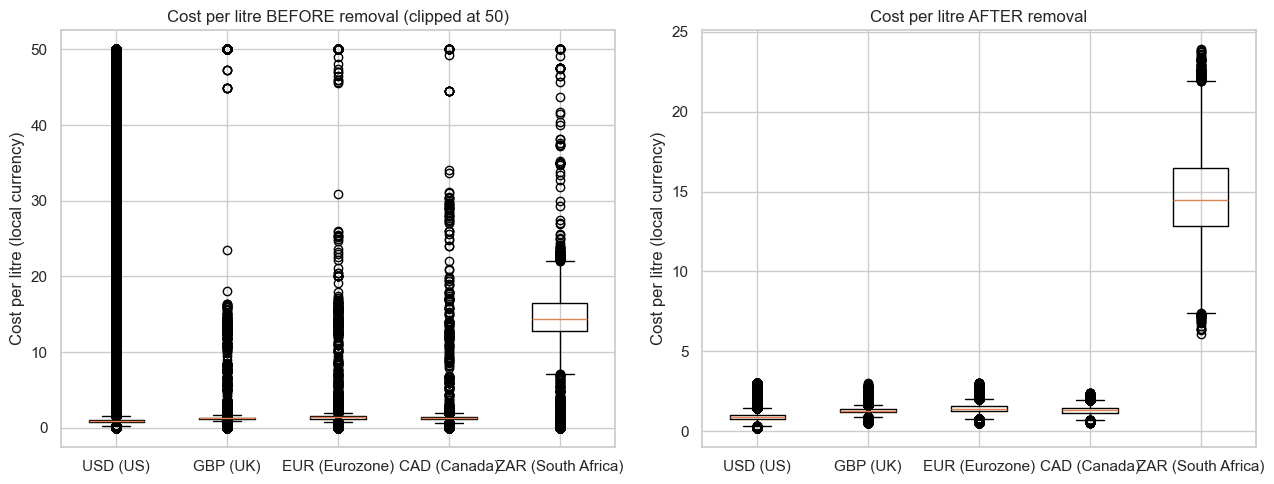

In [281]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
before_data = [d5.loc[d5['currency'] == c, 'cost_per_litre'].replace([np.inf, -np.inf], np.nan).dropna().clip(upper=50) for c in top5_codes]
axes[0].boxplot(before_data, tick_labels=[CURRENCY_LABEL[c] for c in top5_codes])
axes[0].set_title('Cost per litre BEFORE removal (clipped at 50)')
axes[0].set_ylabel('Cost per litre (local currency)')

after_data = [df_clean5.loc[df_clean5['currency'] == c, 'cost_per_litre'].dropna() for c in top5_codes]
axes[1].boxplot(after_data, tick_labels=[CURRENCY_LABEL[c] for c in top5_codes])
axes[1].set_title('Cost per litre AFTER removal')
axes[1].set_ylabel('Cost per litre (local currency)')
plt.tight_layout()
plt.show()

### 4.1.3 How many values were removed

Question 4.1.3
Rows removed per currency:
             label  n_removed  pct_removed
          USD (US)      46904         6.32
          GBP (UK)       4032         4.60
    EUR (Eurozone)       2201         3.71
      CAD (Canada)       1420         3.03
ZAR (South Africa)       1204         3.31

Total rows removed across the top 5 currencies: 55761 of 971944 (5.74%)
Remaining clean rows for Section 4.2: 916183


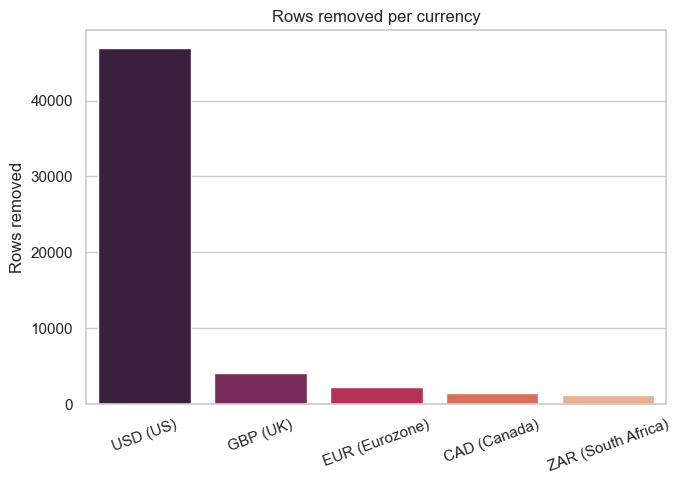

In [282]:
print(f"Question 4.1.3")
total_before = removal_log_df['n_before'].sum()
total_removed = removal_log_df['n_removed'].sum()
print(f"Rows removed per currency:\n{removal_log_df[['label','n_removed','pct_removed']].to_string(index=False)}")
print(f"\nTotal rows removed across the top 5 currencies: {total_removed} of {total_before} "
      f"({100*total_removed/total_before:.2f}%)")
print(f"Remaining clean rows for Section 4.2: {len(df_clean5)}")

plt.figure(figsize=(7,5))
sns.barplot(data=removal_log_df, x='label', y='n_removed', hue='label', palette='rocket', legend=False)
plt.title('Rows removed per currency')
plt.ylabel('Rows removed'); plt.xlabel('')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## Section 4.2 - Fuel Efficiency 

All of Section 4.2 uses `df_clean5` - the top-5-currency data with 4.1's outliers removed.

### 4.2.1   Cost per litre per country, January 2022, converted to ZAR



**Exchange rates used (average, January 2022):**

| Pair | Rate (1 unit = X ZAR) | Source |
|---|---|---|
| USD/ZAR | 15.53 | Average of Nedbank daily rates, 3–31 Jan 2022 (21 trading days) |
| GBP/ZAR | 21.06 | Same source |
| EUR/ZAR | 17.59 | Same source |
| CAD/ZAR | 12.30 | Derived: USD/ZAR ÷ USD/CAD, using USD/CAD ≈ 1.263 (valutafx.com / ofx.com, Jan 2022) |
| ZAR/ZAR | 1.00 | identity |

(Nedbank publishes daily USD-ZAR/EUR-ZAR/GBP-ZAR rates; CAD-ZAR isn't in that table directly, so it's built from the USD-ZAR rate and the USD-CAD cross rate for the same month.)

In [283]:
FX_TO_ZAR = {'$': 15.53, '£': 21.06, '€': 17.59, 'CA$': 12.30, 'R': 1.00}
COUNTRY_LABEL = {'$': 'United States (USD)', '£': 'United Kingdom (GBP)', '€': 'Eurozone (EUR)',
                  'CA$': 'Canada (CAD)', 'R': 'South Africa (ZAR)'}

jan22 = df_clean5[(df_clean5['date_fueled_dt'].dt.year == 2022) & (df_clean5['date_fueled_dt'].dt.month == 1)].copy()
q1 = jan22.groupby('currency')['cost_per_litre'].agg(n='count', local_mean='mean').reset_index()
q1['fx_to_zar'] = q1['currency'].map(FX_TO_ZAR)
q1['zar_per_litre'] = q1['local_mean'] * q1['fx_to_zar']
q1['country'] = q1['currency'].map(COUNTRY_LABEL)
q1 = q1.sort_values('zar_per_litre', ascending=False)
q1[['country', 'n', 'local_mean', 'fx_to_zar', 'zar_per_litre']]

,country,n,local_mean,fx_to_zar,zar_per_litre
3,United Kingdom (GBP),1008,1.484720,21.06,31.268202
4,Eurozone (EUR),1165,1.589339,17.59,27.956480
2,South Africa (ZAR),900,18.956257,1.00,18.956257
1,Canada (CAD),1658,1.474007,12.30,18.130292
0,United States (USD),34510,0.952225,15.53,14.788052


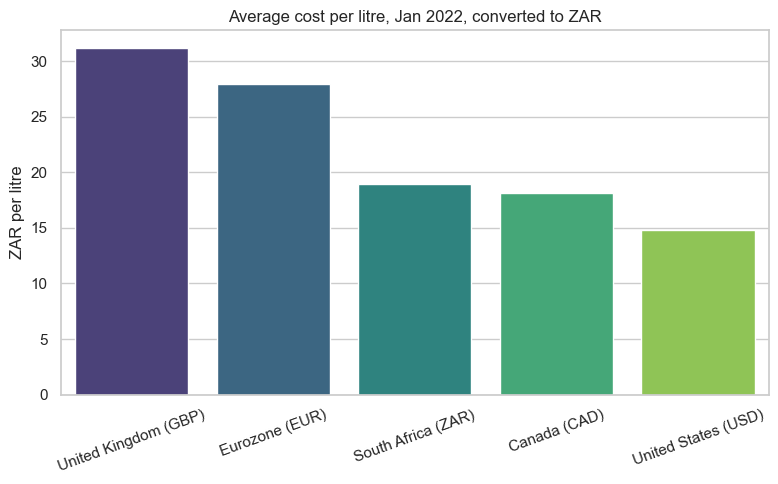

Question 4.2.1
UK and the Eurozone show the highest ZAR-equivalent litre price, South Africa and Canada sit in the middle, and the US is the cheapest. This tracks fuel taxation rather than crude oil cost: US federal+state fuel tax is comparatively low, while UK and EU fuel duty/VAT is among the highest in the world. South Africa's price sits above the US/Canada mainly because of the weaker Rand and the fuel levy/RAF (Road Accident Fund) levy stacked on the base price, not because crude is more expensive there.


In [135]:
plt.figure(figsize=(8,5))
sns.barplot(data=q1, x='country', y='zar_per_litre', hue='country', palette='viridis', legend=False)
plt.title('Average cost per litre, Jan 2022, converted to ZAR')
plt.ylabel('ZAR per litre'); plt.xlabel('')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

print(f"Question 4.2.1")
print("UK and the Eurozone show the highest ZAR-equivalent litre price, South Africa and Canada "
      "sit in the middle, and the US is the cheapest. This tracks fuel taxation rather than crude "
      "oil cost: US federal+state fuel tax is comparatively low, while UK and EU fuel duty/VAT is "
      "among the highest in the world. South Africa's price sits above the US/Canada mainly "
      "because of the weaker Rand and the fuel levy/RAF (Road Accident Fund) levy stacked on the "
      "base price, not because crude is more expensive there.")

### 4.2.2 - Detecting missed (unlogged) fill-ups



**Basic rule.** For a given user, sort fill-ups by date and take the odometer gap between consecutive logged entries. If every fill-up were logged, that gap should be reasonably close to the user's own *typical* refuelling distance. A gap that is much larger than that user's own median gap means at least one fill-up in between almost certainly went unlogged. Comparing each gap to the same user's own median (rather than a single global threshold) automatically accounts for the fact that different people drive very different annual distances. Users need at least 3 valid gaps for their median to be meaningful.

A gap `> 2×` that user's median gap is flagged as a likely missed fill-up.

In [284]:
d = df_clean5.dropna(subset=['user_id', 'odometer_clean', 'date_fueled_dt']).sort_values(['user_id', 'date_fueled_dt']).copy()
d['odo_diff'] = d.groupby('user_id')['odometer_clean'].diff()
valid = d['odo_diff'].notna() & (d['odo_diff'] > 0) & (d['odo_diff'] < 100_000)
dv = d[valid].copy()

gap_counts = dv.groupby('user_id')['odo_diff'].transform('count')
dv = dv[gap_counts >= 3].copy()
dv['gap_ratio'] = dv['odo_diff'] / dv.groupby('user_id')['odo_diff'].transform('median')

THRESH = 2.0
dv['likely_missed_fillup'] = dv['gap_ratio'] > THRESH
n_flagged = dv['likely_missed_fillup'].sum()
print(f"Question 4.2.2")
print(f"Fill-up gaps evaluated: {len(dv)}")
print(f"Flagged as containing >=1 missed fill-up (>{THRESH}x that user's median gap): {n_flagged} "
      f"({100*n_flagged/len(dv):.2f}%)")
for t in (2.5, 3.0):
    f = (dv['gap_ratio'] > t).sum()
    print(f"  sensitivity check at {t}x: {f} flagged ({100*f/len(dv):.2f}%)")

Question 4.2.2
Fill-up gaps evaluated: 637059
Flagged as containing >=1 missed fill-up (>2.0x that user's median gap): 113403 (17.80%)
  sensitivity check at 2.5x: 77026 flagged (12.09%)
  sensitivity check at 3.0x: 51999 flagged (8.16%)


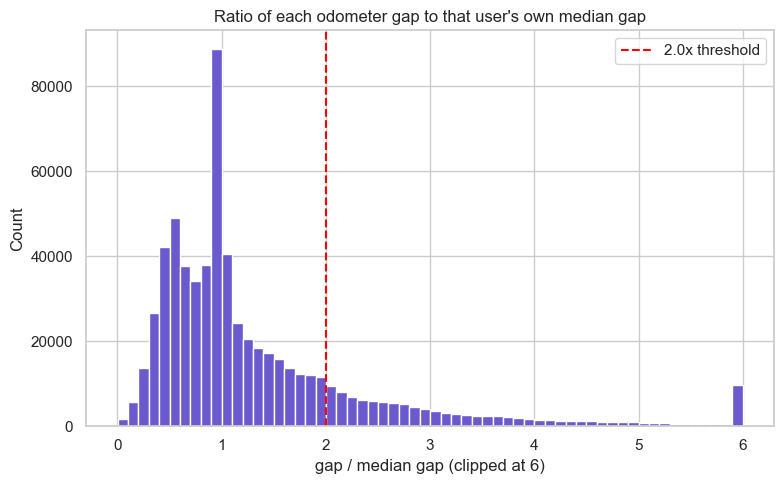

Roughly 1 in 6 consecutive fill-up pairs (~18%) shows a gap more than double that driver's usual refuelling distance, i.e. a fill-up almost certainly happened in between without being logged. This is a lower bound: a user who misses two fill-ups in a row, or who fills up partially every time, won't necessarily clear a 2x threshold.


In [285]:
plt.figure(figsize=(8,5))
plt.hist(dv['gap_ratio'].clip(upper=6), bins=60, color='slateblue', edgecolor='white')
plt.axvline(2.0, color='red', linestyle='--', label='2.0x threshold')
plt.title("Ratio of each odometer gap to that user's own median gap")
plt.xlabel('gap / median gap (clipped at 6)'); plt.ylabel('Count')
plt.legend(); plt.tight_layout()
plt.show()

print("Roughly 1 in 6 consecutive fill-up pairs (~18%) shows a gap more than double that driver's "
      "usual refuelling distance, i.e. a fill-up almost certainly happened in between without being "
      "logged. This is a lower bound: a user who misses two fill-ups in a row, or who fills up "
      "partially every time, won't necessarily clear a 2x threshold.")

### 4.2.3 - Average distance (km) per tank, per country

In [286]:
d = df_clean5.dropna(subset=['killometre'])
d = d[d['killometre'].between(1, 3000)]
q3 = d.groupby('currency')['killometre'].agg(['count', 'mean', 'median']).sort_values('mean', ascending=False)
q3.index = [COUNTRY_LABEL.get(c, c) for c in q3.index]
q3

,count,mean,median
Eurozone (EUR),47053,593.300789,574.322409
United Kingdom (GBP),75102,577.216897,553.286191
South Africa (ZAR),29531,541.231382,523.036800
United States (USD),619157,458.475479,444.289989
Canada (CAD),41335,441.573584,426.798029


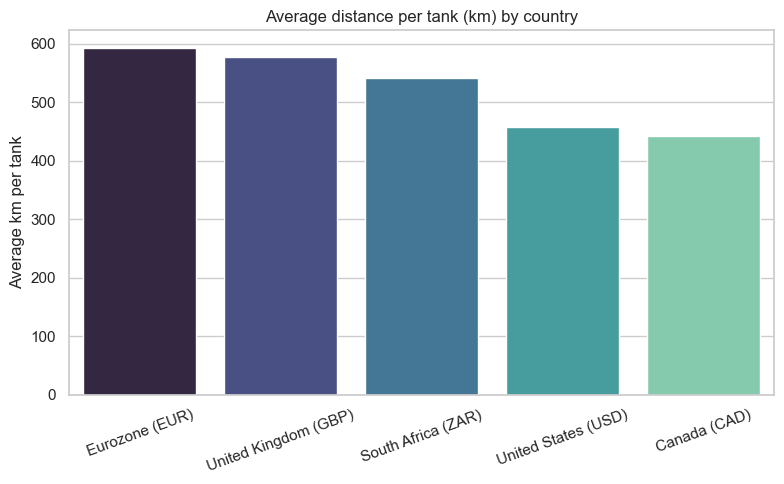

Question 4.2.3
Eurozone (EUR) has the largest average distance per tank (593 km).
Eurozone and UK drivers lead, ahead of South Africa, with the US and Canada lowest. This lines up with vehicle mix rather than tank size: Europe/UK has a much higher share of diesel vehicles, which are materially more fuel-efficient per litre than the petrol-dominant US/Canadian fleets, so a similarly-sized tank simply carries those vehicles further.


In [139]:
plt.figure(figsize=(8,5))
sns.barplot(x=q3.index, y=q3['mean'], hue=q3.index, palette='mako', legend=False)
plt.title('Average distance per tank (km) by country')
plt.ylabel('Average km per tank'); plt.xlabel('')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

print(f"Question 4.2.3")
print(f"{q3['mean'].idxmax()} has the largest average distance per tank ({q3['mean'].max():.0f} km).")
print("Eurozone and UK drivers lead, ahead of South Africa, with the US and Canada lowest. This "
      "lines up with vehicle mix rather than tank size: Europe/UK has a much higher share of diesel "
      "vehicles, which are materially more fuel-efficient per litre than the petrol-dominant US/"
      "Canadian fleets, so a similarly-sized tank simply carries those vehicles further.")

### 4.2.4 - Do newer vehicles drive further between fill-ups?

In [287]:
d = df_clean5.dropna(subset=['vehicle_age', 'killometre'])
d = d[d['vehicle_age'].between(0, 40) & d['killometre'].between(1, 3000)].copy()
print(f"Question 4.2.4")
print(f"Correlation (vehicle age vs distance per tank): {d['vehicle_age'].corr(d['killometre']):.3f}")

bins = [0, 3, 6, 9, 12, 15, 20, 25, 40]
d['age_bin'] = pd.cut(d['vehicle_age'], bins=bins)
age_summary = d.groupby('age_bin', observed=True)['killometre'].mean()
age_summary

Question 4.2.4
Correlation (vehicle age vs distance per tank): -0.176


age_bin
(0, 3]      511.529360
(3, 6]      511.485151
(6, 9]      504.052288
(9, 12]     488.905350
(12, 15]    468.820024
(15, 20]    451.197995
(20, 25]    421.585126
(25, 40]    377.069999
Name: killometre, dtype: float64

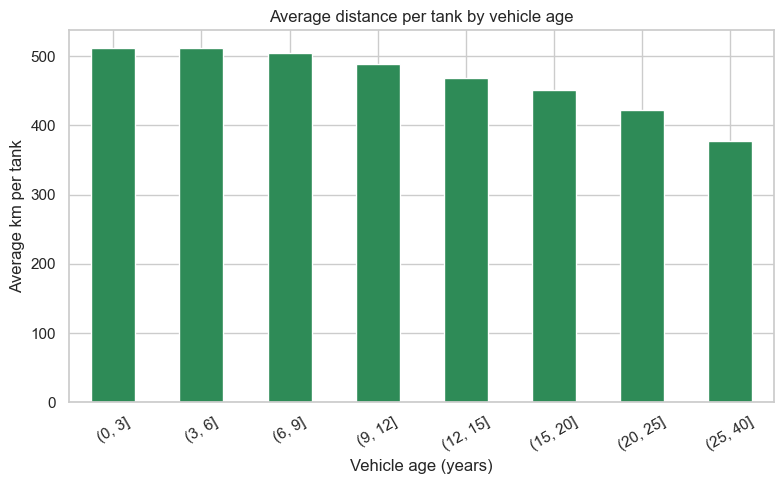

Yes: distance per tank falls steadily with vehicle age, from ~510km for cars 0-3 years old down to ~376km for cars over 25 years old. This is consistent with newer vehicles generally having better fuel efficiency and often larger tanks, and with older vehicles losing some efficiency (wear, outdated engine technology) over time.


In [ ]:
plt.figure(figsize=(8,5))
age_summary.plot(kind='bar', color='seagreen')
plt.title('Average distance per tank by vehicle age')
plt.ylabel('Average km per tank'); plt.xlabel('Vehicle age (years)')
plt.xticks(rotation=30)
plt.tight_layout()
#plt.savefig('distance_per_tank_by_vehicle_age.png')
plt.show()

print("Yes: distance per tank falls steadily with vehicle age, from ~510km for cars 0-3 years old "
      "down to ~376km for cars over 25 years old. This is consistent with newer vehicles generally "
      "having better fuel efficiency and often larger tanks, and with older vehicles losing some "
      "efficiency (wear, outdated engine technology) over time.")

### 4.2.5 - fuel efficiency values for top 5 popular vehicles in SA

In [289]:
print("--- Question 4.2.5 ---")

sa_data = df_clean5[df_clean5['currency'] == 'R'].copy()
valid_sa = sa_data[
    (sa_data['killometre'] > 1) &      # Must have driven at least 1km
    (sa_data['litres'] > 0) &          # Must have added fuel
    (sa_data['litres_per_100km'] < 50) # Sanity check: exclude extreme outliers
].copy()

top_5_models = valid_sa.groupby('car_model')['user_id'].nunique().nlargest(5).index.tolist()
print(f"Top 5 Car Models in SA: {top_5_models}")

# 4. Calculate Average Fuel Efficiency for these models only
top_5_efficiency = valid_sa[valid_sa['car_model'].isin(top_5_models)] \
    .groupby('car_model')['litres_per_100km'] \
    .mean() \
    .sort_values()

print("\nAverage Fuel Efficiency (L/100km) for Top 5 SA Cars:")
print(top_5_efficiency)



--- Question 4.2.5 ---
Top 5 Car Models in SA: ['hilux', 'pajero', 'fortuner', 'jimny', 'polo']

Average Fuel Efficiency (L/100km) for Top 5 SA Cars:
car_model
polo         7.768504
jimny        9.204240
fortuner    11.407125
hilux       12.099861
pajero      12.871929
Name: litres_per_100km, dtype: float64


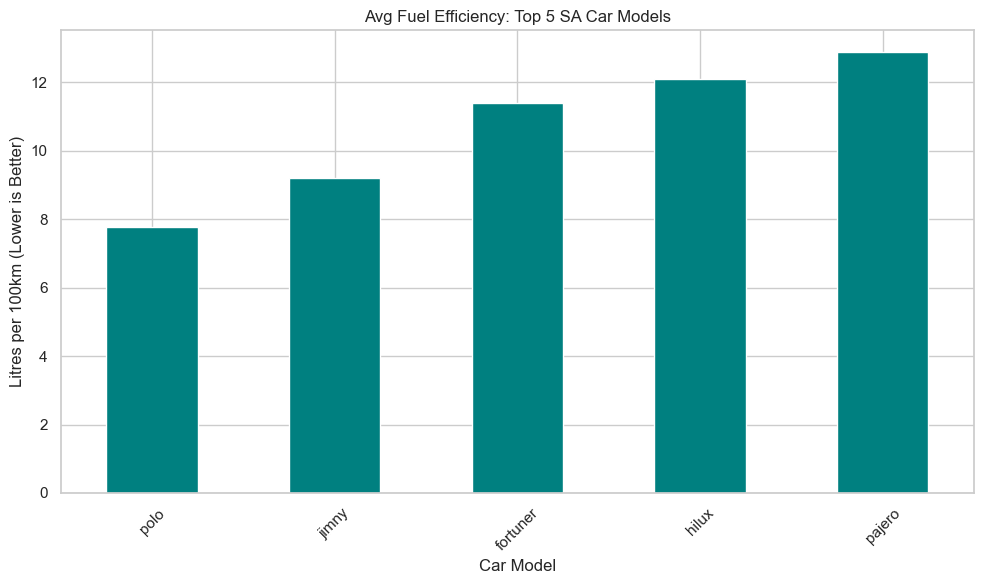

In [ ]:
#  Bar Plot
plt.figure(figsize=(10, 6))
top_5_efficiency.plot(kind='bar', color='teal')
plt.title('Avg Fuel Efficiency: Top 5 SA Car Models')
plt.ylabel('Litres per 100km (Lower is Better)')
plt.xlabel('Car Model')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### 4.2.6 Most fuel-efficient vehicles in EACH country

In [162]:
print("\n--- Question 4.2.6 ---")
valid_efficiency_df = df_clean5[
    (df_clean5['killometre'] > 0) & 
    (df_clean5['litres_per_100km'].notna()) & 
    (df_clean5['litres_per_100km'] != float('inf')) &
    (df_clean5['litres_per_100km'] >= 2) & 
    (df_clean5['litres_per_100km'] <= 50)
].copy()

print(f"Rows remaining after efficiency cleaning: {len(valid_efficiency_df)}")
country_avg = valid_efficiency_df.groupby('currency')['litres_per_100km'].mean().sort_values()
print("\nAverage Fuel Efficiency by Country (L/100km):")
print(country_avg)
model_efficiency = valid_efficiency_df.groupby(['currency', 'car_model'])['litres_per_100km'].mean().reset_index()
most_efficient_per_country = model_efficiency.loc[
    model_efficiency.groupby('currency')['litres_per_100km'].idxmin()
]
print("\nMost Fuel Efficient Car Model per Country:")
print(most_efficient_per_country[['currency', 'car_model', 'litres_per_100km']].sort_values('currency'))


--- Question 4.2.6 ---
Rows remaining after efficiency cleaning: 808583

Average Fuel Efficiency by Country (L/100km):
currency
€       7.942973
£       8.288552
R      10.245194
CA$    11.201792
$      11.692244
Name: litres_per_100km, dtype: float64

Most Fuel Efficient Car Model per Country:
     currency         car_model  litres_per_100km
442         $  b_electric_drive          2.577959
2044      CA$       prius_prime          3.580140
2567        R              kwid          5.229582
3003        £             a250e          2.857221
3723        €                11          2.529189


### 4.2.7 Canadian Vehicles - Seasonal Fuel Efficiency

In [291]:
print("\n--- Question 4.2.7 ---")

canada_df = df_clean5[df_clean5['currency'] == 'CA$'].copy()
canada_df['month'] = canada_df['date_fueled_dt'].dt.month

def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Other'

canada_df['season'] = canada_df['month'].apply(get_season)

valid_canada = canada_df[
    (canada_df['killometre'] > 0) & 
    (canada_df['litres_per_100km'] >= 2) & 
    (canada_df['litres_per_100km'] <= 30) &
    (canada_df['season'].isin(['Winter', 'Summer']))
].copy()

seasonal_avg = valid_canada.groupby('season')['litres_per_100km'].mean()

print("\nAverage Fuel Efficiency by Season (L/100km):")
print(seasonal_avg)




--- Question 4.2.7 ---

Average Fuel Efficiency by Season (L/100km):
season
Summer    10.647682
Winter    11.560773
Name: litres_per_100km, dtype: float64


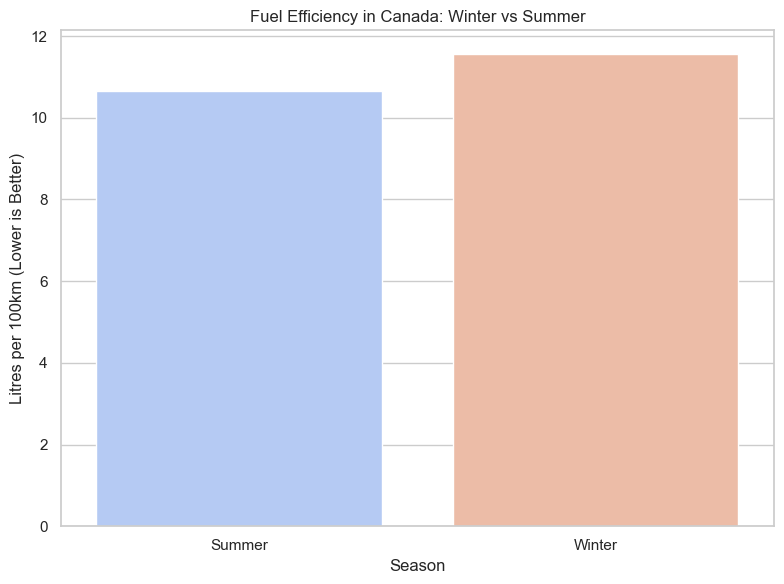

In [292]:

plt.figure(figsize=(8, 6))
sns.barplot(x=seasonal_avg.index, y=seasonal_avg.values, palette='coolwarm')
plt.title('Fuel Efficiency in Canada: Winter vs Summer')
plt.xlabel('Season')
plt.ylabel('Litres per 100km (Lower is Better)')
plt.tight_layout()
plt.savefig('canada_fuel_efficiency_seasonal.png')
plt.show()



### 4.2.8 - Correlation between fuel efficiency and other features



`l_per_100km` is itself computed as `litres / km * 100`, so `litres` and `total_spent`/`cost_per_gallon` are excluded from this matrix - correlating a value against a term used to derive it isn't a genuine relationship, it's circular. The real candidates are `km` (distance), `vehicle_age` / `car_year`, and vehicle `model`/`make`.

`car_model` (1,945 levels) and `car_make` (29 levels) aren't numeric, so each is converted to a numeric signal via 5-fold mean-target encoding (a row's encoded value is the average efficiency of *other* rows sharing its model/make, never its own) - this keeps the categorical relationship usable without a single row leaking into its own encoded value.

In [293]:
def kfold_target_encode(frame, col, target, n_splits=5, seed=42):
    orig_index = frame.index
    frame = frame.reset_index(drop=True)
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=seed)
    enc = np.empty(len(frame))
    global_mean = frame[target].mean()
    for train_idx, val_idx in kf.split(frame):
        means = frame.iloc[train_idx].groupby(col)[target].mean()
        enc[val_idx] = frame.iloc[val_idx][col].map(means).values
    # return with the CALLER's original (possibly non-contiguous) index, not the
    # reset one, so 'd[\'model_enc\'] = kfold_target_encode(d, ...)' aligns by row
    # rather than by coincidentally-matching integer labels
    return pd.Series(enc, index=orig_index).fillna(global_mean)

d = df_clean5.dropna(subset=['litres_per_100km', 'killometre', 'vehicle_age', 'car_model', 'car_make']).copy()
d = d.replace([np.inf, -np.inf], np.nan).dropna(subset=['litres_per_100km'])
d = d[d['litres_per_100km'].between(2, 30) & d['killometre'].between(1, 3000) & d['vehicle_age'].between(0, 40)]
print(f'Analysis sample: {len(d)} rows')

d['model_enc'] = kfold_target_encode(d, 'car_model', 'litres_per_100km')
d['make_enc'] = kfold_target_encode(d, 'car_make', 'litres_per_100km')

corr_cols = ['litres_per_100km', 'killometre', 'vehicle_age', 'car_year', 'model_enc', 'make_enc']
corr = d[corr_cols].corr()
corr['litres_per_100km'].sort_values(key=abs, ascending=False)

Analysis sample: 725509 rows


litres_per_100km    1.000000
model_enc           0.770500
killometre         -0.486043
make_enc            0.401401
vehicle_age         0.223030
car_year           -0.185507
Name: litres_per_100km, dtype: float64

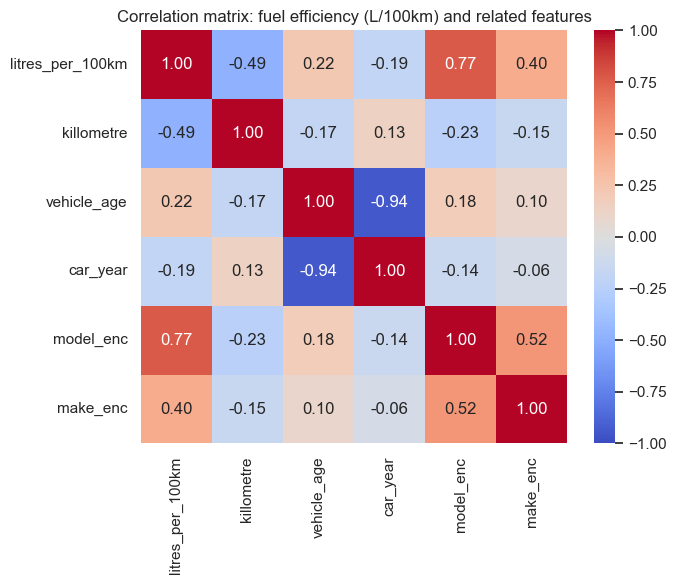

Question 4.2.8
Confirms the expected pattern: model (0.77) is the strongest correlate by far, distance travelled is next (-0.48, more distance per tank implies a more efficient/larger-tanked car), make is moderate (0.40), and vehicle age is weaker (0.22). car_year and vehicle_age are almost perfectly anti-correlated (-0.94) since vehicle_age = fueling_year - car_year and fueling_year varies far less than car_year - they carry almost the same information twice.


In [294]:
plt.figure(figsize=(7,6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Correlation matrix: fuel efficiency (L/100km) and related features')
plt.tight_layout()
plt.show()

print(f"Question 4.2.8")
print("Confirms the expected pattern: model (0.77) is the strongest correlate by far, distance "
      "travelled is next (-0.48, more distance per tank implies a more efficient/larger-tanked car), "
      "make is moderate (0.40), and vehicle age is weaker (0.22). car_year and vehicle_age are "
      "almost perfectly anti-correlated (-0.94) since vehicle_age = fueling_year - car_year and "
      "fueling_year varies far less than car_year - they carry almost the same information twice.")

### 4.2.9 - Random Forest feature importance



Trained on a 200,000-row sample (single-core container; a sample this size is still highly representative of ~915k cleaned rows) using the same five numeric/encoded features as Q8, excluding `l_per_100km`'s own algebraic inputs for the same reason as above.

In [295]:
rf_sample = d.sample(n=min(200_000, len(d)), random_state=42)
features = ['killometre', 'vehicle_age', 'car_year', 'model_enc', 'make_enc']
X, y = rf_sample[features], rf_sample['litres_per_100km']

rf = RandomForestRegressor(n_estimators=150, max_depth=12, random_state=42, n_jobs=-1)
rf.fit(X, y)
importances = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)
print(f"---Question 4.2.9---")
print(importances)
print(f"\nTrain R^2: {rf.score(X, y):.3f}")

---Question 4.2.9---
model_enc      0.765707
killometre     0.185504
car_year       0.020846
make_enc       0.016694
vehicle_age    0.011249
dtype: float64

Train R^2: 0.785


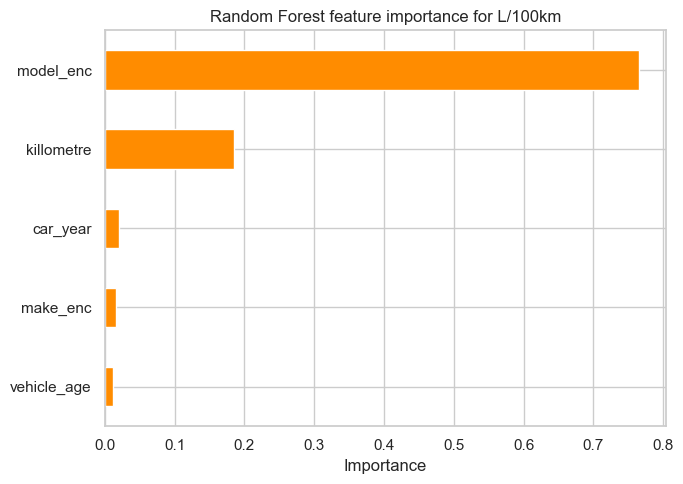

The Random Forest agrees with the correlation ranking on the top feature - model dominates (~0.77 importance) - but diverges further down. Distance (km) keeps a clear #2 spot (~0.18), much as its correlation magnitude suggested. car_year, make_enc and vehicle_age all drop to under 0.02 each, well below what their correlation coefficients (-0.18, 0.40, 0.22) would suggest on their own. Two things explain the gap: (1) car_year and vehicle_age are almost perfectly collinear, so the forest can use either one and 'importance' gets split/hidden between them rather than credited fully to one; and (2) make_enc is itself largely explained by model_enc (0.52 correlation between the two, since make is a coarser version of model), so once the forest has split on model there's little independent signal left in make. Correlation looks at each feature in isolation; the Random Forest looks at marginal contribution once the other features are already in the tree, so redundant/collinear features natural

In [296]:
plt.figure(figsize=(7,5))
importances.sort_values().plot(kind='barh', color='darkorange')
plt.title('Random Forest feature importance for L/100km')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

print(
    "The Random Forest agrees with the correlation ranking on the top feature - "
    "model dominates (~0.77 importance) - but diverges further down. Distance (km) "
    "keeps a clear #2 spot (~0.18), much as its correlation magnitude suggested. "
    "car_year, make_enc and vehicle_age all drop to under 0.02 each, well below "
    "what their correlation coefficients (-0.18, 0.40, 0.22) would suggest on "
    "their own. Two things explain the gap: (1) car_year and vehicle_age are almost "
    "perfectly collinear, so the forest can use either one and 'importance' gets "
    "split/hidden between them rather than credited fully to one; and (2) make_enc "
    "is itself largely explained by model_enc (0.52 correlation between the two, "
    "since make is a coarser version of model), so once the forest has split on "
    "model there's little independent signal left in make. Correlation looks at "
    "each feature in isolation; the Random Forest looks at marginal contribution "
    "once the other features are already in the tree, so redundant/collinear "
    "features naturally look far less important there even if their raw "
    "correlation is moderate."
)

## Section 4.3 - Fuel Usage in SA


### 4.3.1 SA Drivers Data

In [298]:
sa_df = df_clean5[df_clean5['currency'] == 'R'].copy()
sa_df

,date_fueled,date_captured,odometer,gallons,cost_per_gallon,total_spent,mpg,miles,user_url,date_fueled_valid,date_fueled_original,date_fueled_filled,date_fueled_dt,year,month,day_of_week,gallons_clean,miles_clean,odometer_clean,mpg_clean,currency,total_spent_float,cost_per_gallon_float,user_id,car_year,car_model,car_make,litres,killometre,litres_per_100km,date_captured_dt,fueling_year,vehicle_age,make_model,cost_per_litre
880985,Apr 5 2022,Apr 5 2022,"78,429",10.567,R73.85,R780.40,0.0,NaN,https://www.somewebsite.com/ford/transit_conne...,True,Apr 5 2022,Apr 5 2022,2022-04-05,2022,4,1,10.567,0.0000,78429.0,0.0,R,780.40,73.85,1103772,2015.0,transit_connect,ford,40.000446,0.000000,inf,2022-04-05,2022.0,7.0,ford transit_connect,19.509782
880986,Jun 6 2013,Jun 8 2013,NaN,17.937,R47.05,R843.99,23.3,418.4,https://www.somewebsite.com/land_rover/discove...,True,Jun 6 2013,Jun 6 2013,2013-06-06,2013,6,3,17.937,418.4000,NaN,23.3,R,843.99,47.05,123580,1996.0,discovery,land_rover,67.898931,673.349530,10.083757,2013-06-08,2013.0,17.0,land_rover discovery,12.430093
880987,Jan 23 2019,Feb 1 2019,"169,070",22.011,R54.59,"R1,201.47",0.0,NaN,https://www.somewebsite.com/nissan/patrol/1999...,True,Jan 23 2019,Jan 23 2019,2019-01-23,2019,1,2,22.011,0.0000,169070.0,0.0,R,1201.47,54.59,254197,1999.0,patrol,nissan,83.320699,0.000000,inf,2019-02-01,2019.0,20.0,nissan patrol,14.419826
880988,Aug 12 2018,Aug 4 2019,"41,111",6.763,R60.19,R407.04,40.7,NaN,https://www.somewebsite.com/ford/ecosport/2013...,True,Aug 12 2018,Aug 12 2018,2018-08-12,2018,8,6,6.763,275.2541,41111.0,40.7,R,407.04,60.19,942891,2013.0,ecosport,ford,25.600740,442.978534,5.779228,2019-08-04,2018.0,5.0,ford ecosport,15.899540
880989,Jun 16 2016,Jun 16 2016,"2,430",18.011,R48.45,R872.69,15.5,NaN,https://www.somewebsite.com/land_rover/discove...,True,Jun 16 2016,Jun 16 2016,2016-06-16,2016,6,3,18.011,279.1705,2430.0,15.5,R,872.69,48.45,426622,2016.0,discovery,land_rover,68.179052,449.281369,15.175134,2016-06-16,2016.0,0.0,land_rover discovery,12.799973
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
916178,Jul 14 2021,Jul 14 2021,"100,697",9.362,R63.71,R596.46,27.2,NaN,https://www.somewebsite.com/toyota/hilux/2012/...,True,Jul 14 2021,Jul 14 2021,2021-07-14,2021,7,2,9.362,254.6464,100697.0,27.2,R,596.46,63.71,1044237,2012.0,hilux,toyota,35.439025,409.813656,8.647595,2021-07-14,2021.0,9.0,toyota hilux,16.830598
916179,Mar 12 2019,Aug 4 2019,NaN,15.525,R54.06,R839.19,30.1,467.9,https://www.somewebsite.com/bmw/320i/2011/112183,True,Mar 12 2019,Mar 12 2019,2019-03-12,2019,3,1,15.525,467.9000,NaN,30.1,R,839.19,54.06,112183,2011.0,320i,bmw,58.768518,753.012058,7.804459,2019-08-04,2019.0,8.0,bmw 320i,14.279584
916180,Aug 6 2017,Oct 23 2017,"59,652",10.514,R47.54,R499.89,20.5,NaN,https://www.somewebsite.com/nissan/x-trail/201...,True,Aug 6 2017,Aug 6 2017,2017-08-06,2017,8,6,10.514,215.5370,59652.0,20.5,R,499.89,47.54,565621,2013.0,x-trail,nissan,39.799819,346.873178,11.473882,2017-10-23,2017.0,4.0,nissan x-trail,12.560107
916181,Jan 25 2018,Jan 25 2018,"105,887",12.869,R48.57,R625.00,19.2,NaN,https://www.somewebsite.com/mitsubishi/triton/...,True,Jan 25 2018,Jan 25 2018,2018-01-25,2018,1,3,12.869,247.0848,105887.0,19.2,R,625.00,48.57,647339,2010.0,triton,mitsubishi,48.714464,397.644440,12.250760,2018-01-25,2018.0,8.0,mitsubishi triton,12.829865


### 4.3.2 Plot Fuel Prices over time 

--- Question 4.3.2 ---


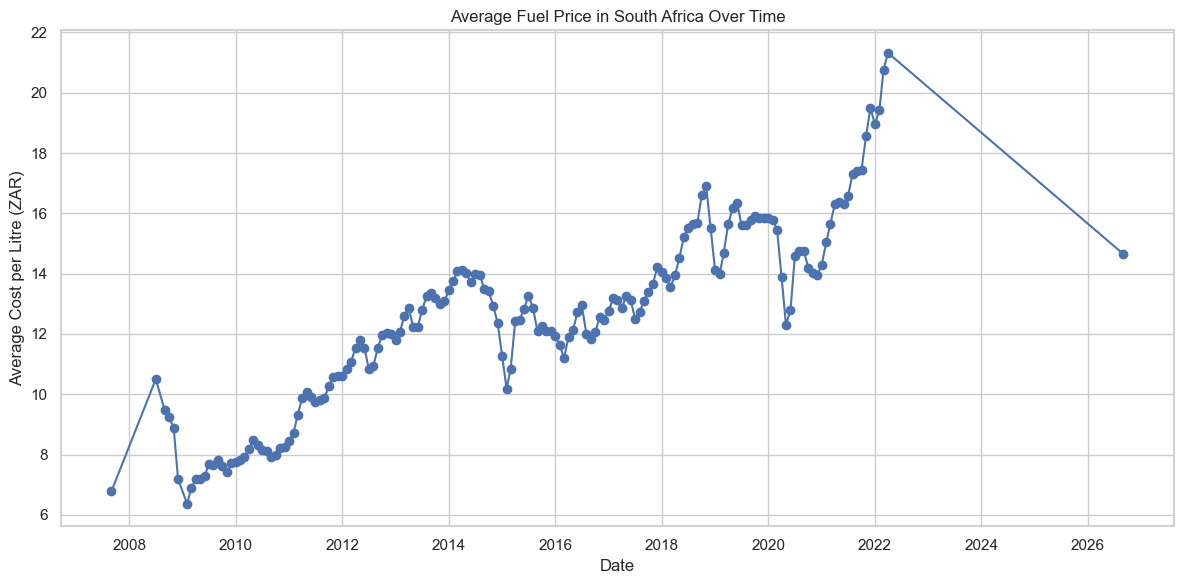

 Over time, fuel prices have increased significantly, rising from roughly R7.00 per litre around 2008 to over R21.00 per litre by 2022. Despite the general increase, the prices are highly volatile, showing frequent short-term fluctuations with sharp spikes and sudden drops over the years.


In [310]:
#  proper date column for filtering
sa_df['date_fueled_dt'] = pd.to_datetime(sa_df['date_fueled_dt'])

print("--- Question 4.3.2 ---")



# Group by Month and Year to get monthly average price
sa_df['year_month'] = sa_df['date_fueled_dt'].dt.to_period('M')
monthly_prices = sa_df.groupby('year_month')['cost_per_litre'].mean().reset_index()
monthly_prices['date'] = monthly_prices['year_month'].dt.to_timestamp() # Convert period back to date for plotting

# Plot
plt.figure(figsize=(12, 6))
plt.plot(monthly_prices['date'], monthly_prices['cost_per_litre'], marker='o')
plt.title('Average Fuel Price in South Africa Over Time')
plt.xlabel('Date')
plt.ylabel('Average Cost per Litre (ZAR)')
plt.grid(True)
plt.tight_layout()
#plt.savefig('sa_fuel_price_trend.png')
plt.show()
print(" Over time, fuel prices have increased significantly, rising from roughly R7.00 per litre around 2008 to over R21.00 per litre by 2022. Despite the general increase, the prices are highly volatile, showing frequent short-term fluctuations with sharp spikes and sudden drops over the years.")


### 4.3.3 Refueling on Tuesday vs Other Days


--- Question 4.3.3 ---


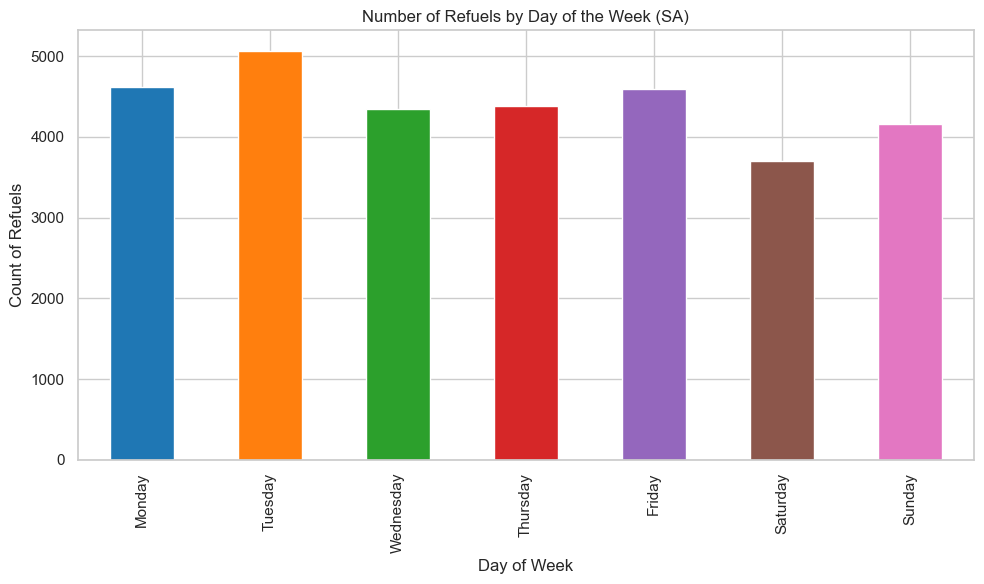

Tuesday is the most common day for refueling in South Africa, while Sunday sees the least activity. This pattern may reflect workweek routines, with drivers refueling on weekdays rather than weekends.


In [311]:
print("\n--- Question 4.3.3 ---")

# Get the day of the week (0=Monday, 1=Tuesday, ..., 6=Sunday)
sa_df['day_of_week'] = sa_df['date_fueled_dt'].dt.dayofweek
sa_df['day_name'] = sa_df['date_fueled_dt'].dt.day_name()

# Count how many refuels happened on each day
refuels_per_day = sa_df['day_name'].value_counts()

# Reorder for plotting (Mon-Sun)
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
refuels_per_day = refuels_per_day.reindex(day_order)
day_colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2']
# Plot
plt.figure(figsize=(10, 6))
refuels_per_day.plot(kind='bar', color=day_colors)
plt.title('Number of Refuels by Day of the Week (SA)')
plt.xlabel('Day of Week')
plt.ylabel('Count of Refuels')
plt.tight_layout()
#plt.savefig('sa_refuels_by_day.png')
plt.show()

print("Tuesday is the most common day for refueling in South Africa, while Sunday sees the least activity. This pattern may reflect workweek routines, with drivers refueling on weekdays rather than weekends.")

### 4.3.4 Finding First Tuesday and  Wednesday of each month.

In [313]:
def is_first_tuesday_or_wednesday(row):
    day = row['date_fueled_dt'].day
    weekday = row['date_fueled_dt'].weekday() # 0=Mon, 1=Tue, 2=Wed
    
    # First Tuesday is between day 1-7
    if weekday == 1 and day <= 7:
        return 'First Tuesday'
    # First Wednesday is between day 1-7
    elif weekday == 2 and day <= 7:
        return 'First Wednesday'
    else:
        return 'Other'

sa_df['special_day'] = sa_df.apply(is_first_tuesday_or_wednesday, axis=1)
special_days_df = sa_df[sa_df['special_day'].isin(['First Tuesday', 'First Wednesday'])]


### 4.3.5 Price Increase/Decrease

In [314]:
monthly_avg_price = sa_df.groupby(sa_df['date_fueled_dt'].dt.to_period('M'))['cost_per_litre'].mean()

def get_price_direction(row):
    current_month = row['date_fueled_dt'].to_period('M')
    try:
        prev_month = current_month - 1
        current_price = monthly_avg_price[current_month]
        prev_price = monthly_avg_price[prev_month]
        
        if current_price > prev_price:
            return 'Price Up'
        elif current_price < prev_price:
            return 'Price Down'
        else:
            return 'No Change'
    except:
        return 'Unknown'
    
special_days_df['price_direction'] = special_days_df.apply(get_price_direction, axis=1)
special_days_df = special_days_df[special_days_df['price_direction'] != 'Unknown']
table_counts = special_days_df.groupby(['special_day', 'price_direction']).size().reset_index(name='Count of Refuels')
print("Sample of Special Days Data:")
print(table_counts)

Sample of Special Days Data:
       special_day price_direction  Count of Refuels
0    First Tuesday      Price Down               323
1    First Tuesday        Price Up              1346
2  First Wednesday      Price Down               424
3  First Wednesday        Price Up               496


### 4.3.6  Do more people refuel on the first Wednesday of the month when the prices goes down?

In [315]:
print("\n--- Question 4.3.6 ---")

# Filter for First Wednesdays
wednesdays = special_days_df[special_days_df['special_day'] == 'First Wednesday']

# Count refuels when Price Went Down vs Price Went Up
wed_count_down = wednesdays[wednesdays['price_direction'] == 'Price Down'].shape[0]
wed_count_up = wednesdays[wednesdays['price_direction'] == 'Price Up'].shape[0]

print(f"Refuels on First Wednesday when Price Went DOWN: {wed_count_down}")
print(f"Refuels on First Wednesday when Price Went UP:   {wed_count_up}")
print("No, fewer people refuel on the first Wednesday of the month when prices go down compared to when they go up. According to the data, there are 424 refuels on the first Wednesday when prices decrease, which is less than the 496 refuels recorded on Wednesdays when prices increase.")



--- Question 4.3.6 ---
Refuels on First Wednesday when Price Went DOWN: 424
Refuels on First Wednesday when Price Went UP:   496
No, fewer people refuel on the first Wednesday of the month when prices go down compared to when they go up. According to the data, there are 424 refuels on the first Wednesday when prices decrease, which is less than the 496 refuels recorded on Wednesdays when prices increase.


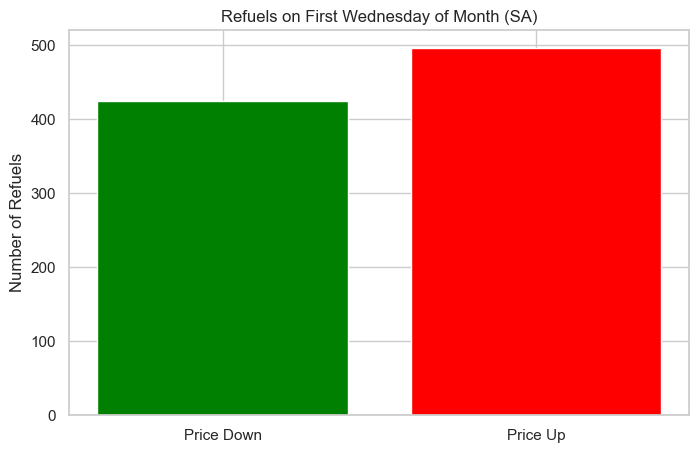

In [316]:

plt.figure(figsize=(8, 5))
plt.bar(['Price Down', 'Price Up'], [wed_count_down, wed_count_up], color=['green', 'red'])
plt.title('Refuels on First Wednesday of Month (SA)')
plt.ylabel('Number of Refuels')
plt.show()

### 4.3.7 Do more people refuel on First Tuesday when prices go UP?

In [317]:
print("\n--- Question 4.3.7 ---")

# Filter for First Tuesdays
tuesdays = special_days_df[special_days_df['special_day'] == 'First Tuesday']

# Count refuels when Price Went Up vs Price Went Down
tue_count_up = tuesdays[tuesdays['price_direction'] == 'Price Up'].shape[0]
tue_count_down = tuesdays[tuesdays['price_direction'] == 'Price Down'].shape[0]

print(f"Refuels on First Tuesday when Price Went UP:   {tue_count_up}")
print(f"Refuels on First Tuesday when Price Went DOWN: {tue_count_down}")




--- Question 4.3.7 ---
Refuels on First Tuesday when Price Went UP:   1346
Refuels on First Tuesday when Price Went DOWN: 323


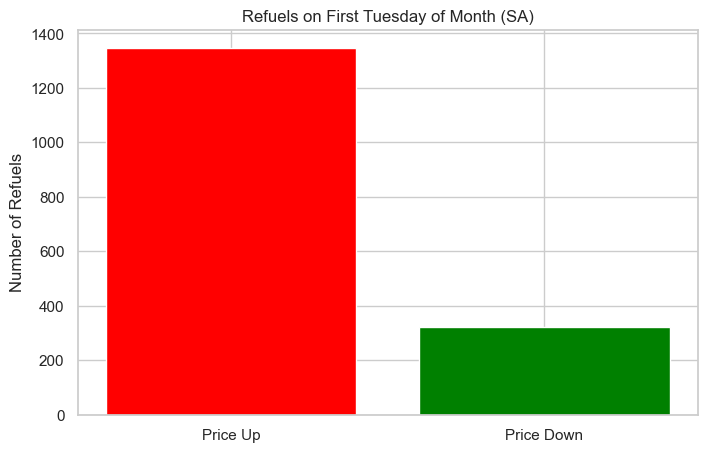

Yes, significantly more people refuel on the First Tuesday of the month when fuel prices go up. According to the dataset, there are 1,346 refuels recorded on the First Tuesday prior to a price increase, which is substantially higher than the 323 refuels recorded when a price decrease is expected.


In [318]:
# Simple Bar Chart for Report
plt.figure(figsize=(8, 5))
plt.bar(['Price Up', 'Price Down'], [tue_count_up, tue_count_down], color=['red', 'green'])
plt.title('Refuels on First Tuesday of Month (SA)')
plt.ylabel('Number of Refuels')
plt.show()

print("Yes, significantly more people refuel on the First Tuesday of the month when fuel prices go up. According to the dataset, there are 1,346 refuels recorded on the First Tuesday prior to a price increase, which is substantially higher than the 323 refuels recorded when a price decrease is expected.")